<a href="https://colab.research.google.com/github/santyxd3000/Fault-Detection-Classification-SD/blob/main/AnomalyDetectionMethods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **UNDERGRADUATE PROJECT**

Santiago Ivan Pardo Morales

In [376]:
#For using the GPU
#!git clone https://github.com/rapidsai/rapidsai-csp-utils.git
#!python rapidsai-csp-utils/colab/pip-install.py

In [377]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
import datetime
import scipy
sns.set()
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
import io
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score
from sklearn import model_selection
from sklearn.datasets import make_classification
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.neural_network import MLPRegressor
#import cudf
#import cuml
#import cupy as cp
#from cuml import preprocessing as cpp
import tensorflow as tf
from keras.layers import Input, Dropout, Dense, LSTM, TimeDistributed, RepeatVector
from keras.models import Model
from keras import regularizers
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
physical_devices = tf.config.list_physical_devices('GPU')
from sklearn.covariance import MinCovDet
from sklearn.model_selection import GridSearchCV
from scipy.stats import chi2
from sklearn.covariance import EllipticEnvelope

In [378]:
print("GPU:", tf.config.list_physical_devices('GPU'))
print("Num GPUs:", len(physical_devices))

GPU: []
Num GPUs: 0


In [379]:
#Visual Studio / GitHub
'''
filtered_data = pd.read_csv('filtered_data.csv',sep=';').dropna()
normal_operation_data = pd.read_csv('normal_operation_data.csv',sep=';').dropna()
anomaly_data = pd.read_csv('anomaly_data.csv',sep=';').dropna()
'''

"\nfiltered_data = pd.read_csv('filtered_data.csv',sep=';').dropna()\nnormal_operation_data = pd.read_csv('normal_operation_data.csv',sep=';').dropna()\nanomaly_data = pd.read_csv('anomaly_data.csv',sep=';').dropna()\n"

In [380]:
#Google Colab

#from google.colab import files
#uploaded = files.upload()


In [381]:
#Google Colab

filtered_data = pd.read_csv('filtered_data.csv',sep=';').dropna()
normal_operation_data = pd.read_csv('normal_operation_data.csv',sep=';').dropna()
anomaly_data = pd.read_csv('anomaly_data.csv',sep=';').dropna()


**DATA ANALYSIS**

*Datos conjuntos*

Text(0, 0.5, 'Frequency')

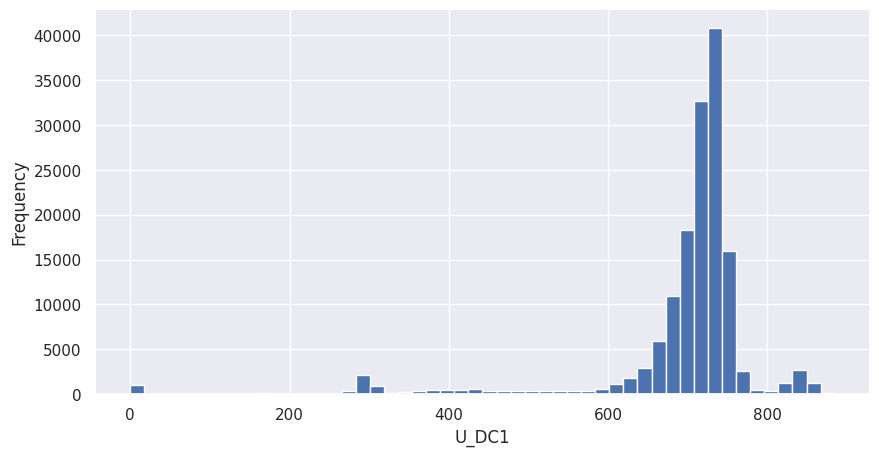

In [382]:
plt.figure(figsize=(10,5))
plt.hist(filtered_data["U_DC1"],bins=50)
plt.xlabel('U_DC1')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

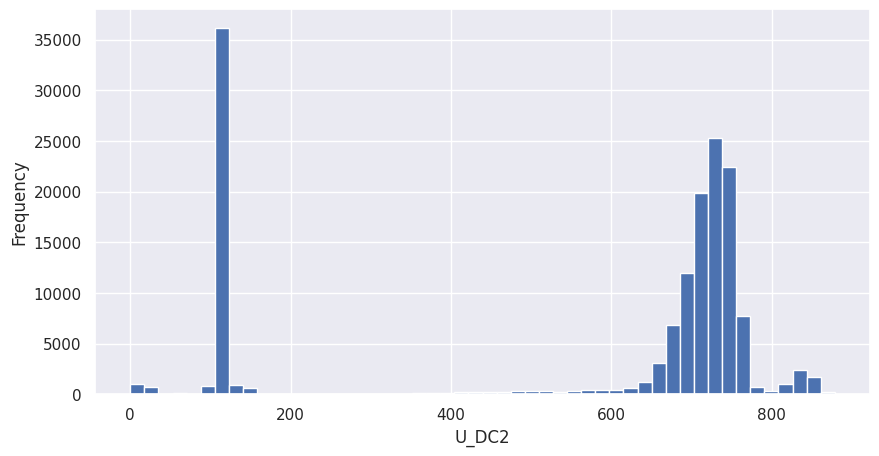

In [383]:
plt.figure(figsize=(10,5))
plt.hist(filtered_data["U_DC2"],bins=50)
plt.xlabel('U_DC2')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

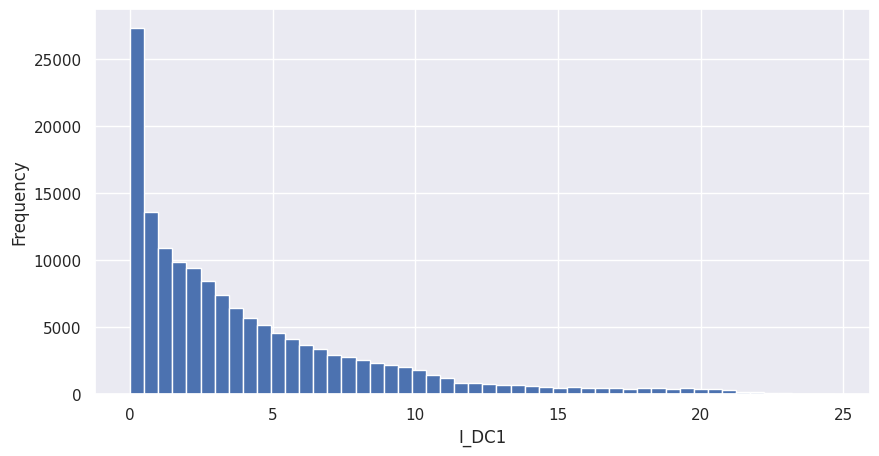

In [384]:
plt.figure(figsize=(10,5))
plt.hist(filtered_data["I_DC1"],bins=50)
plt.xlabel('I_DC1')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

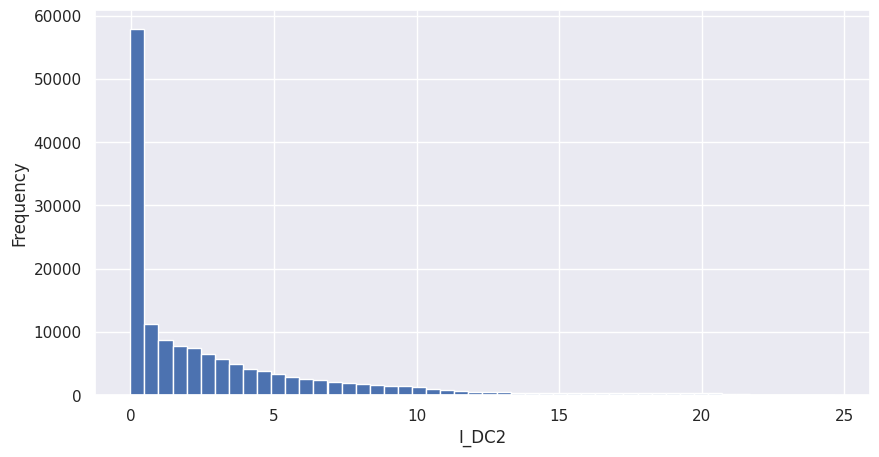

In [385]:
plt.figure(figsize=(10,5))
plt.hist(filtered_data["I_DC2"],bins=50)
plt.xlabel('I_DC2')
plt.ylabel('Frequency')

*Training Data*

Text(0, 0.5, 'Frequency')

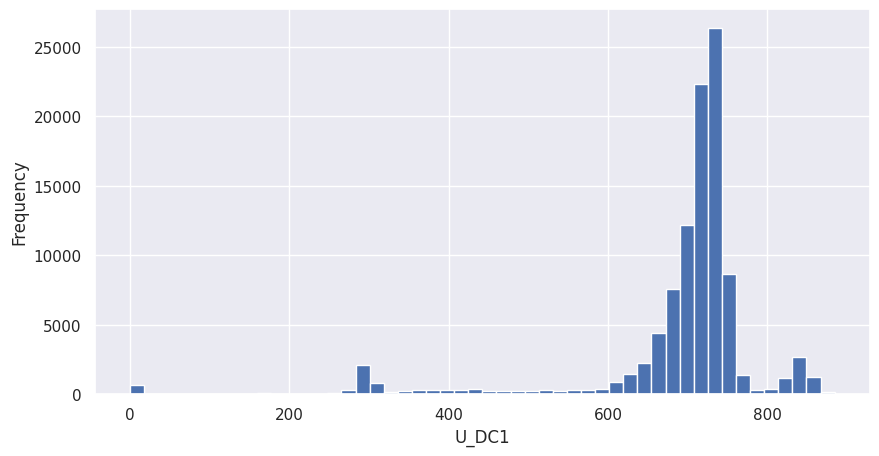

In [386]:
plt.figure(figsize=(10,5))
plt.hist(normal_operation_data["U_DC1"],bins=50)
plt.xlabel('U_DC1')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

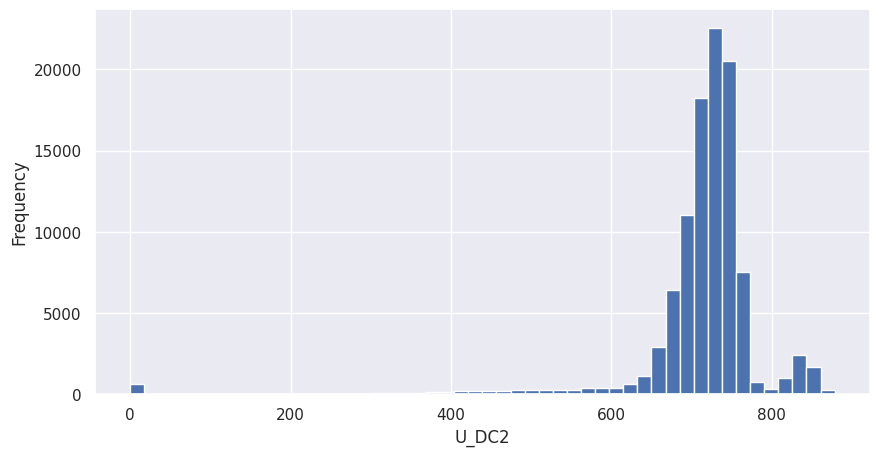

In [387]:
plt.figure(figsize=(10,5))
plt.hist(normal_operation_data["U_DC2"],bins=50)
plt.xlabel('U_DC2')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

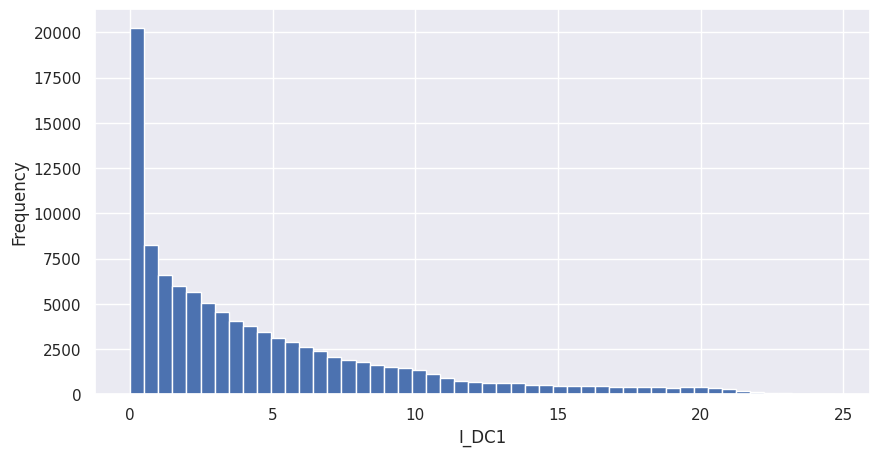

In [388]:
plt.figure(figsize=(10,5))
plt.hist(normal_operation_data["I_DC1"],bins=50)
plt.xlabel('I_DC1')
plt.ylabel('Frequency')

Text(0, 0.5, 'Frequency')

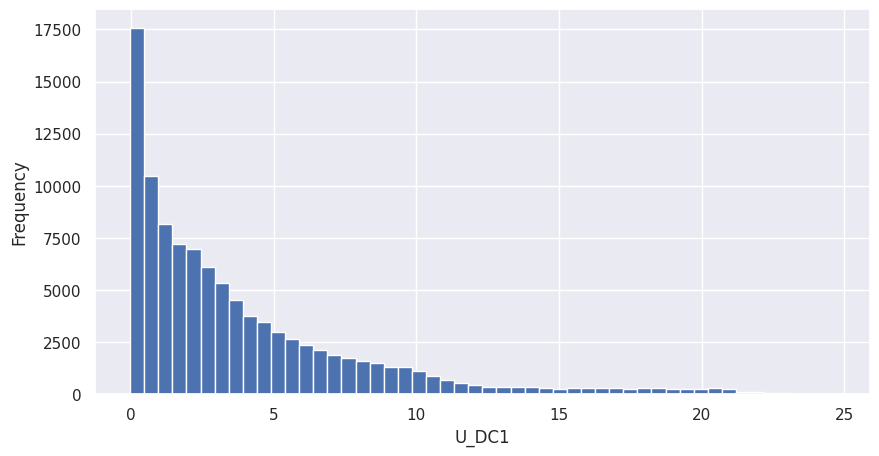

In [389]:
plt.figure(figsize=(10,5))
plt.hist(normal_operation_data["I_DC2"],bins=50)
plt.xlabel('U_DC1')
plt.ylabel('Frequency')

*Correlation matrix*

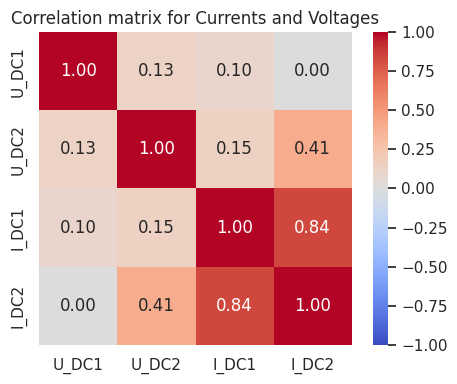

In [390]:
cols = ["U_DC1", "U_DC2", "I_DC1", "I_DC2"]
corr = filtered_data[cols].corr()

plt.figure(figsize=(5,4))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, square=True, cbar=True, cmap="coolwarm")
plt.title("Correlation matrix for Currents and Voltages")
plt.tight_layout()
plt.show()

## **MÉTODO ESTADÍSTICO -  RANGO INTERCUARTIL**

### *Datos de entrenamiento*

In [391]:
statistical_df_train = normal_operation_data
statistical_df_test = anomaly_data
statistical_df_train.Timestamp = pd.to_datetime(statistical_df_train.Timestamp, format='%Y-%m-%d %H:%M:%S')
statistical_df_train["Time"] = statistical_df_train.Timestamp.dt.time
statistical_df_test.Timestamp = pd.to_datetime(statistical_df_test.Timestamp, format='%Y-%m-%d %H:%M:%S')
statistical_df_test["Time"] = statistical_df_test.Timestamp.dt.time

Text(0, 0.5, 'Current of the system [A]')

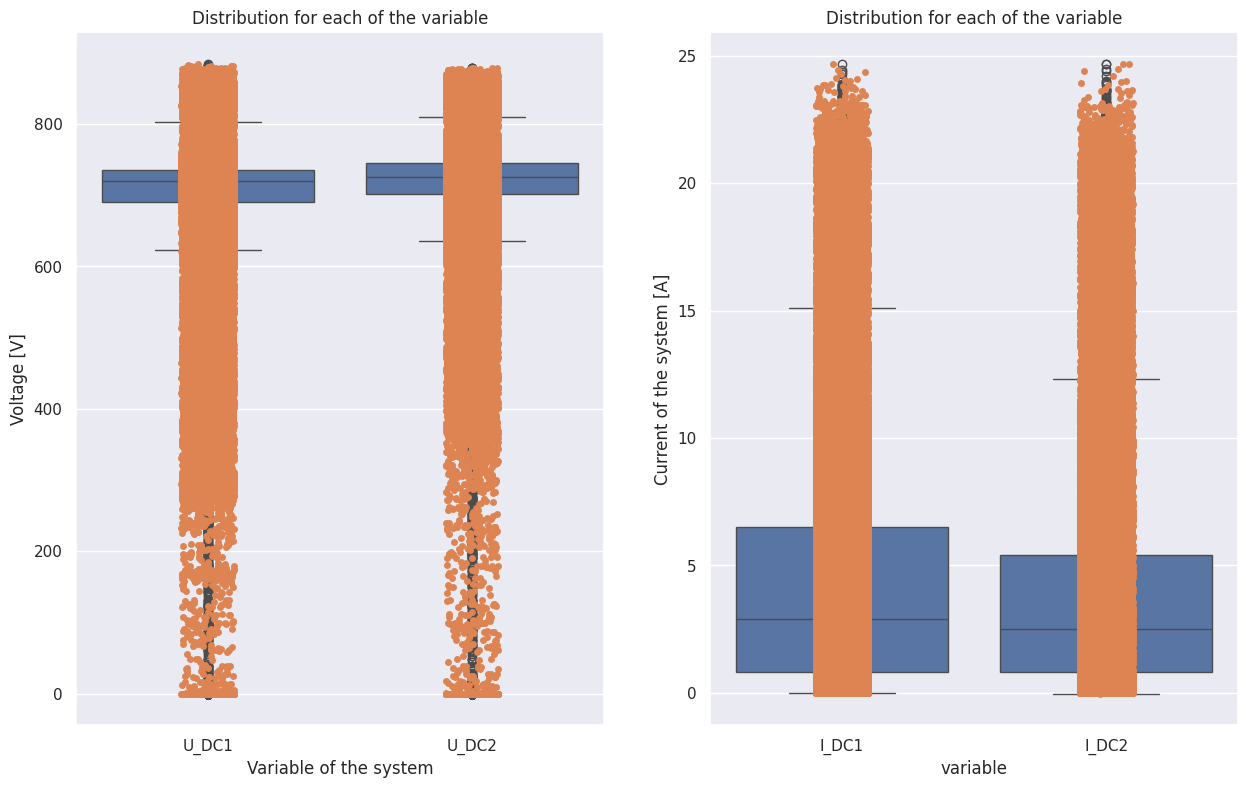

In [392]:
a = statistical_df_train[["U_DC1","U_DC2"]].melt()
b = statistical_df_train[["I_DC1","I_DC2"]].melt()
fig, axes = plt.subplots(1,2,figsize=(15,9))
sns.boxplot(x="variable",y="value",data=a,ax=axes[0])
sns.stripplot(data = a, x= "variable",y="value",ax=axes[0])
axes[0].set_title("Distribution for each of the variable")
axes[0].set_xlabel("Variable of the system")
axes[0].set_ylabel("Voltage [V]")

sns.boxplot(x="variable",y="value",data=b,ax=axes[1])
sns.stripplot(data = b, x= "variable",y="value",ax=axes[1])
plt.title("Distribution for each of the variable")
plt.ylabel("Current of the system [A]")

/tmp/ipykernel_6487/453591921.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="variable", y="value", data=a, ax=axes[0], width=0.4, palette="Blues")
/tmp/ipykernel_6487/453591921.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="variable", y="value", data=b, ax=axes[1], width=0.4, palette="Oranges")


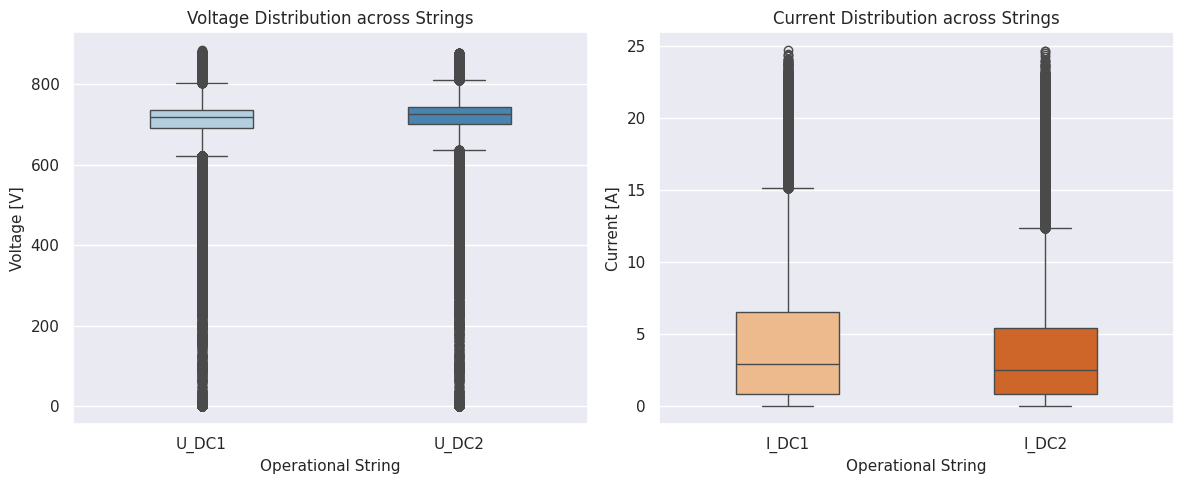

In [444]:
import matplotlib.pyplot as plt
import seaborn as sns


a = statistical_df_train[["U_DC1", "U_DC2"]].melt()
b = statistical_df_train[["I_DC1", "I_DC2"]].melt()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.boxplot(x="variable", y="value", data=a, ax=axes[0], width=0.4, palette="Blues")
axes[0].set_title("Voltage Distribution across Strings", fontsize=12)
axes[0].set_xlabel("Operational String", fontsize=11)
axes[0].set_ylabel("Voltage [V]", fontsize=11)


sns.boxplot(x="variable", y="value", data=b, ax=axes[1], width=0.4, palette="Oranges")
axes[1].set_title("Current Distribution across Strings", fontsize=12)
axes[1].set_xlabel("Operational String", fontsize=11)
axes[1].set_ylabel("Current [A]", fontsize=11)


plt.tight_layout()
plt.show()

In [393]:
q1_group = statistical_df_train.groupby('Time')[['U_DC1','U_DC2','I_DC1','I_DC2']].agg(lambda x: x.quantile(0.25)).reset_index()
q3_group = statistical_df_train.groupby('Time')[['U_DC1','U_DC2','I_DC1','I_DC2']].agg(lambda x: x.quantile(0.75)).reset_index()

In [394]:
time = np.array(q1_group['Time'])

In [395]:
q1_group1 = q1_group[['U_DC1','U_DC2','I_DC1','I_DC2']]
q3_group1 = q3_group[['U_DC1','U_DC2','I_DC1','I_DC2']]

iqr_group1 = q3_group1-q1_group1
iqr_group = iqr_group1
iqr_group['Time'] = time
iqr_group1 = iqr_group1.drop('Time',axis=1)

In [396]:
lower_iqr = q1_group1 - 3*iqr_group1
upper_iqr = q3_group1 + 3*iqr_group1

In [397]:
iqr_values = pd.DataFrame()
iqr_values['Upper_UDC1'] = upper_iqr[['U_DC1']]
iqr_values['Upper_UDC2'] = upper_iqr[['U_DC2']]
iqr_values['Upper_IDC1'] = upper_iqr[['I_DC1']]
iqr_values['Upper_IDC2'] = upper_iqr[['I_DC2']]
iqr_values['Lower_UDC1'] = lower_iqr[['U_DC1']]
iqr_values['Lower_UDC2'] = lower_iqr[['U_DC2']]
iqr_values['Lower_IDC1'] = lower_iqr[['I_DC1']]
iqr_values['Lower_IDC2'] = lower_iqr[['I_DC2']]
iqr_values['Time'] = time

In [398]:
merged_df_train = pd.merge(statistical_df_train, iqr_values, how="inner", on=["Time"])

In [399]:
merged_df_train['Anomaly_UDC1'] = np.where((merged_df_train['U_DC1'] < merged_df_train['Lower_UDC1']) | (merged_df_train['U_DC1'] > merged_df_train['Upper_UDC1']), 1,0)
merged_df_train['Anomaly_UDC2'] = np.where((merged_df_train['U_DC2'] < merged_df_train['Lower_UDC2']) | (merged_df_train['U_DC2'] > merged_df_train['Upper_UDC2']), 1,0)
merged_df_train['Anomaly_IDC1'] = np.where((merged_df_train['I_DC1'] < merged_df_train['Lower_IDC1']) | (merged_df_train['I_DC1'] > merged_df_train['Upper_IDC1']), 1,0)
merged_df_train['Anomaly_IDC2'] = np.where((merged_df_train['I_DC2'] < merged_df_train['Lower_IDC2']) | (merged_df_train['I_DC2'] > merged_df_train['Upper_IDC2']), 1,0)
merged_df_train['Anomaly_String1'] = np.where((merged_df_train['Anomaly_UDC1'] == 1) | (merged_df_train['Anomaly_IDC1'] == 1), 1,0)
merged_df_train['Anomaly_String2'] = np.where((merged_df_train['Anomaly_UDC2'] == 1) | (merged_df_train['Anomaly_IDC2'] == 1), 1,0)
merged_df_train.loc[:,'Anomaly'] = np.where(
    (merged_df_train['Anomaly_String1'] == 1) |
    (merged_df_train['Anomaly_String2'] == 1),
    1,
    0
)
merged_df_train = merged_df_train.sort_values(by=['Timestamp'])

In [400]:
count0 = (merged_df_train['Anomaly'] == 0).sum()
count1 = (merged_df_train['Anomaly'] == 1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

93306 8930


In [401]:
anomaly_iqr_train = merged_df_train[merged_df_train['Anomaly'] == 1]
no_anomaly_iqr_train = merged_df_train[merged_df_train['Anomaly'] == 0]

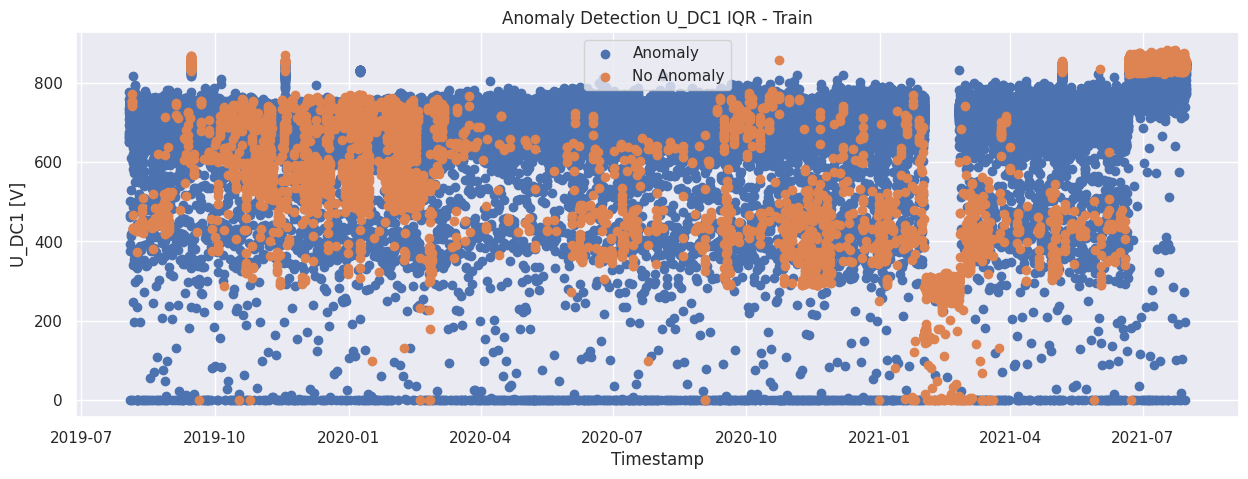

In [402]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_train['Timestamp'],no_anomaly_iqr_train['U_DC1'])
plt.scatter(anomaly_iqr_train['Timestamp'],anomaly_iqr_train['U_DC1'])
plt.xlabel('Timestamp')
plt.ylabel('U_DC1 [V]')
plt.title('Anomaly Detection U_DC1 IQR - Train')
plt.legend(['Anomaly','No Anomaly'])

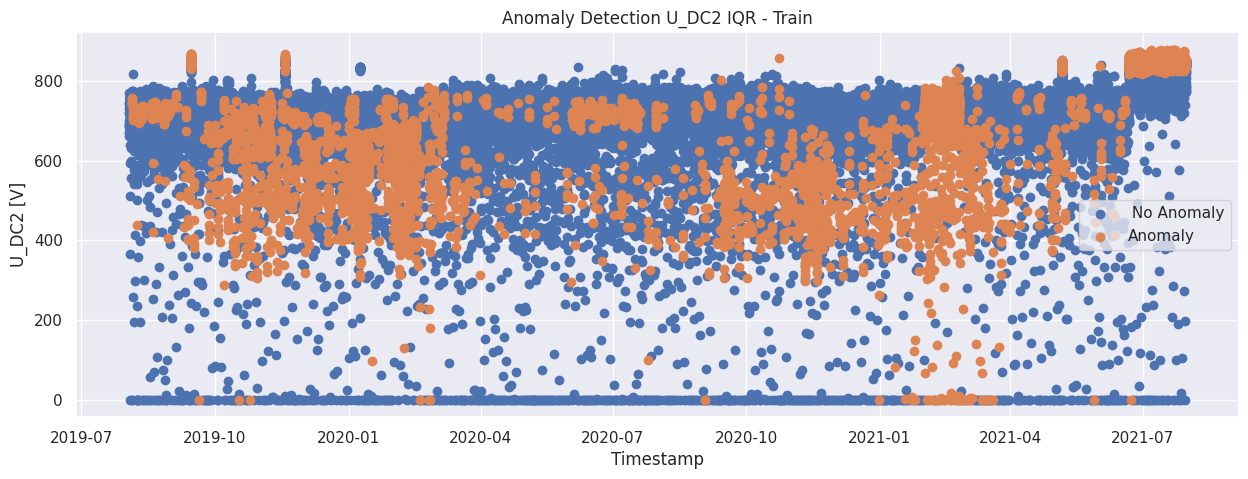

In [403]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_train['Timestamp'],no_anomaly_iqr_train['U_DC2'])
plt.scatter(anomaly_iqr_train['Timestamp'],anomaly_iqr_train['U_DC2'])
plt.xlabel('Timestamp')
plt.ylabel('U_DC2 [V]')
plt.title('Anomaly Detection U_DC2 IQR - Train')
plt.legend([' No Anomaly','Anomaly'])

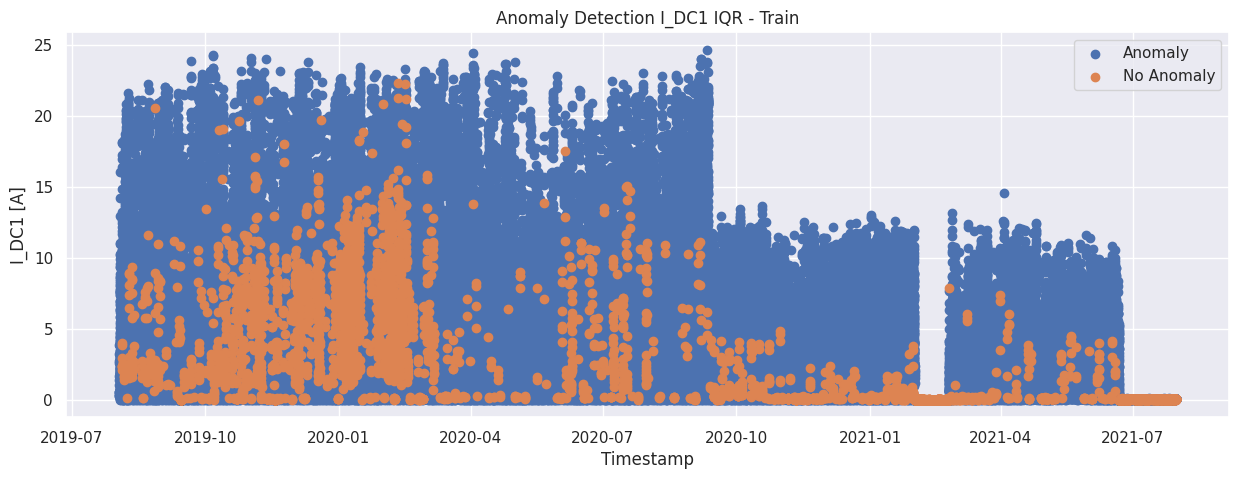

In [404]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_train['Timestamp'],no_anomaly_iqr_train['I_DC1'])
plt.scatter(anomaly_iqr_train['Timestamp'],anomaly_iqr_train['I_DC1'])
plt.xlabel('Timestamp')
plt.ylabel('I_DC1 [A]')
plt.title('Anomaly Detection I_DC1 IQR - Train')
plt.legend(['Anomaly','No Anomaly'])

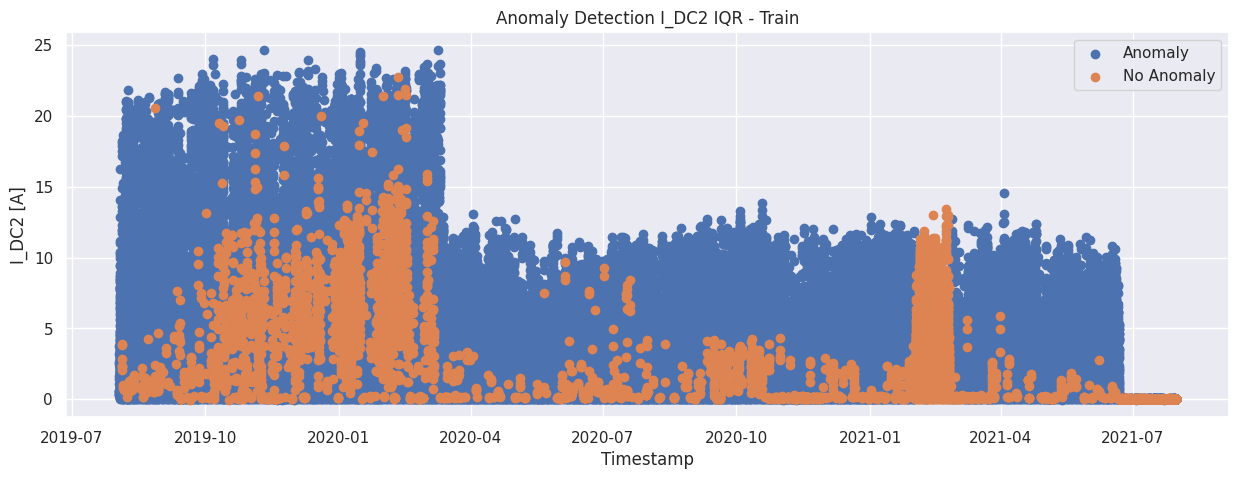

In [405]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_train['Timestamp'],no_anomaly_iqr_train['I_DC2'])
plt.scatter(anomaly_iqr_train['Timestamp'],anomaly_iqr_train['I_DC2'])
plt.xlabel('Timestamp')
plt.ylabel('I_DC2 [A]')
plt.title('Anomaly Detection I_DC2 IQR - Train')
plt.legend(['Anomaly','No Anomaly'])

In [406]:
merged_df_train

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Time,Upper_UDC1,Upper_UDC2,Upper_IDC1,Upper_IDC2,...,Lower_UDC2,Lower_IDC1,Lower_IDC2,Anomaly_UDC1,Anomaly_UDC2,Anomaly_IDC1,Anomaly_IDC2,Anomaly_String1,Anomaly_String2,Anomaly
0,2019-08-02 16:25:00,777.010,768.710,2.700,2.607,16:25:00,923.7590,886.0335,8.4615,5.5035,...,544.7240,-5.3775,-3.0575,0,0,0,0,0,0,0
1,2019-08-02 16:30:00,761.130,745.964,3.862,3.748,16:30:00,894.4745,880.3615,7.7855,5.1540,...,549.4995,-4.8810,-2.8470,0,0,0,0,0,0,0
2,2019-08-02 16:35:00,736.754,742.908,3.228,3.192,16:35:00,901.4545,886.9950,7.6950,4.9345,...,542.3745,-4.9155,-2.7480,0,0,0,0,0,0,0
3,2019-08-02 16:40:00,731.928,732.224,2.568,2.484,16:40:00,897.8275,876.7320,6.6050,4.4035,...,549.6115,-4.1400,-2.3725,0,0,0,0,0,0,0
4,2019-08-02 16:45:00,723.546,720.698,1.654,1.640,16:45:00,884.6805,877.0080,5.9200,4.2875,...,552.2990,-3.6700,-2.3520,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102231,2021-07-30 17:10:00,788.168,788.084,0.020,0.050,17:10:00,879.9830,853.7770,3.5355,2.5220,...,545.4655,-2.1940,-1.3560,0,0,0,0,0,0,0
102232,2021-07-30 17:15:00,780.194,780.138,0.020,0.050,17:15:00,876.8885,844.2770,3.0220,2.2355,...,547.4665,-1.8710,-1.2050,0,0,0,0,0,0,0
102233,2021-07-30 17:20:00,772.618,772.588,0.020,0.050,17:20:00,885.7275,837.7750,2.5680,1.8875,...,544.8880,-1.5795,-1.0035,0,0,0,0,0,0,0
102234,2021-07-30 17:25:00,775.204,775.162,0.020,0.050,17:25:00,890.7275,837.6390,2.2820,1.6360,...,535.2110,-1.4315,-0.8630,0,0,0,0,0,0,0


In [407]:
merged_df_train['Anomaly'].unique()

array([0, 1])

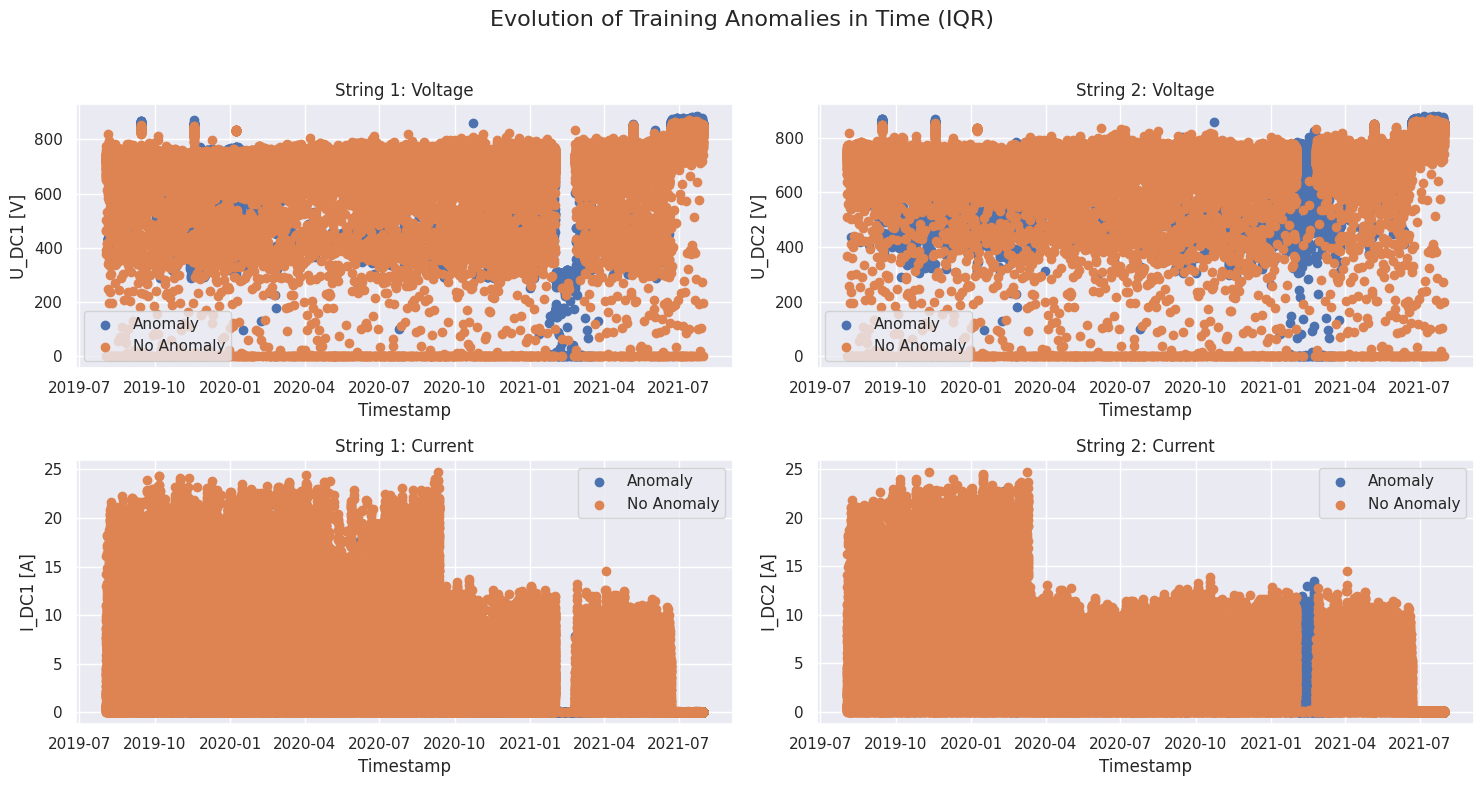

In [446]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
plt.suptitle('Evolution of Training Anomalies in Time (IQR)', fontsize=16)

# --- Subplot 1: Voltage String 1 (Top Left) ---
plt.subplot(2, 2, 1)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['U_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['U_DC1'], label='No Anomaly')
plt.xlabel('Timestamp')
plt.ylabel('U_DC1 [V]')
plt.title('String 1: Voltage')
plt.legend()

# --- Subplot 2: Voltage String 2 (Top Right) ---
plt.subplot(2, 2, 2)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['U_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['U_DC2'], label='No Anomaly')
plt.xlabel('Timestamp')
plt.ylabel('U_DC2 [V]')
plt.title('String 2: Voltage')
plt.legend()

# --- Subplot 3: Current String 1 (Bottom Left) ---
plt.subplot(2, 2, 3)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('Timestamp')
plt.ylabel('I_DC1 [A]')
plt.title('String 1: Current')
plt.legend()

# --- Subplot 4: Current String 2 (Bottom Right) ---
plt.subplot(2, 2, 4)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('Timestamp')
plt.ylabel('I_DC2 [A]')
plt.title('String 2: Current')
plt.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

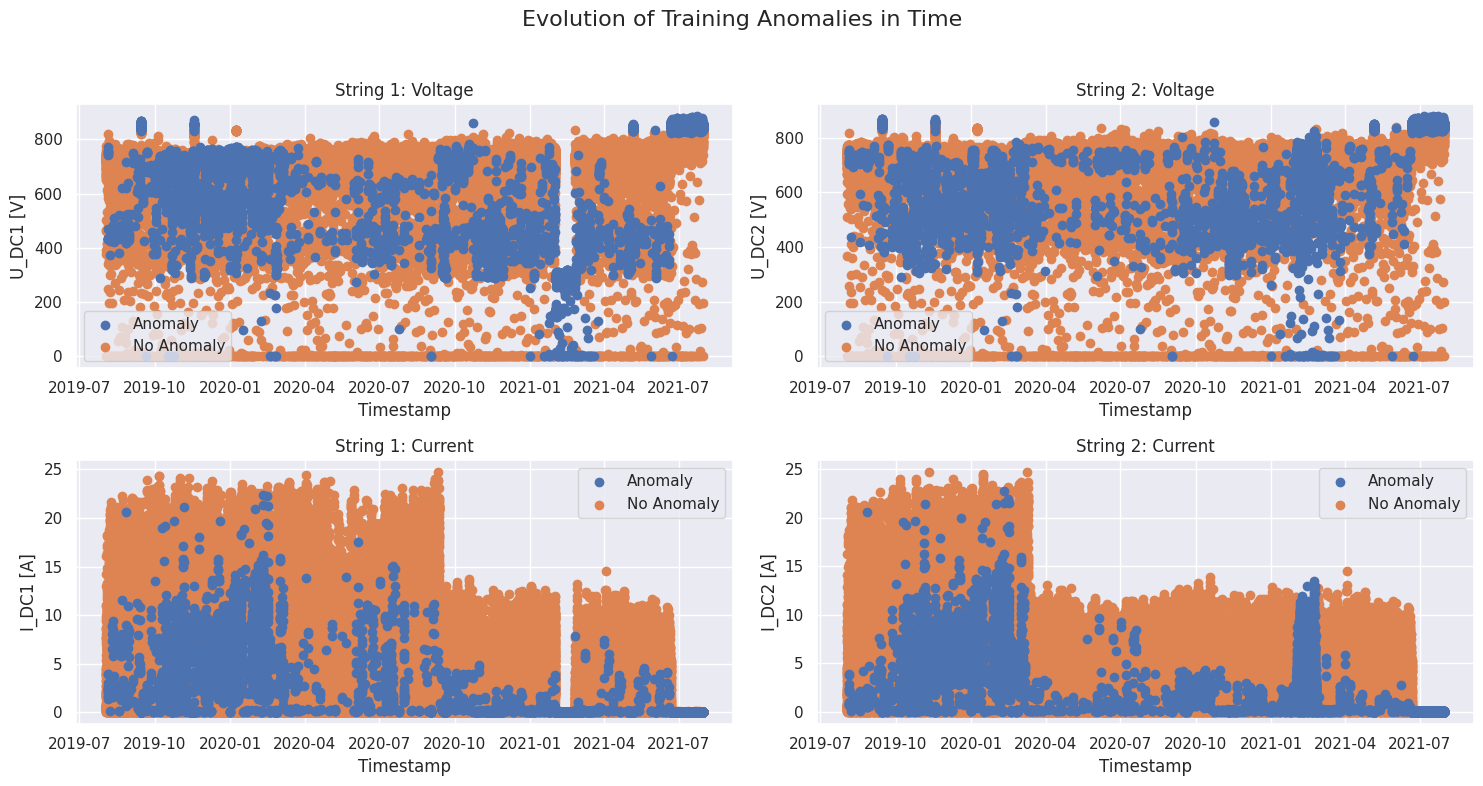

In [454]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
plt.suptitle('Evolution of Training Anomalies in Time', fontsize=16)

# --- Subplot 1: Voltage String 1 (Top Left) ---
plt.subplot(2, 2, 1)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['U_DC1'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['U_DC1'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('U_DC1 [V]')
plt.title('String 1: Voltage')
plt.legend()

# --- Subplot 2: Voltage String 2 (Top Right) ---
plt.subplot(2, 2, 2)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['U_DC2'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['U_DC2'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('U_DC2 [V]')
plt.title('String 2: Voltage')
plt.legend()

# --- Subplot 3: Current String 1 (Bottom Left) ---
plt.subplot(2, 2, 3)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['I_DC1'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('I_DC1 [A]')
plt.title('String 1: Current')
plt.legend()

# --- Subplot 4: Current String 2 (Bottom Right) ---
plt.subplot(2, 2, 4)
plt.scatter(anomaly_iqr_train['Timestamp'], anomaly_iqr_train['I_DC2'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_train['Timestamp'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('I_DC2 [A]')
plt.title('String 2: Current')
plt.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### *Datos de prueba*

In [408]:
#Group with test data
merged_df_test = pd.merge(anomaly_data, iqr_values, how="inner", on=["Time"])

In [409]:
merged_df_test['Anomaly_UDC1'] = np.where((merged_df_test['U_DC1'] < merged_df_test['Lower_UDC1']) | (merged_df_test['U_DC1'] > merged_df_test['Upper_UDC1']), 1,0)
merged_df_test['Anomaly_UDC2'] = np.where((merged_df_test['U_DC2'] < merged_df_test['Lower_UDC2']) | (merged_df_test['U_DC2'] > merged_df_test['Upper_UDC2']), 1,0)
merged_df_test['Anomaly_IDC1'] = np.where((merged_df_test['I_DC1'] < merged_df_test['Lower_IDC1']) | (merged_df_test['I_DC1'] > merged_df_test['Upper_IDC1']), 1,0)
merged_df_test['Anomaly_IDC2'] = np.where((merged_df_test['I_DC2'] < merged_df_test['Lower_IDC2']) | (merged_df_test['I_DC2'] > merged_df_test['Upper_IDC2']), 1,0)

merged_df_test['Anomaly_String1'] = np.where((merged_df_test['Anomaly_UDC1'] == 1) | (merged_df_test['Anomaly_IDC1'] == 1), 1,0)
merged_df_test['Anomaly_String2'] = np.where((merged_df_test['Anomaly_UDC2'] == 1) | (merged_df_test['Anomaly_IDC2'] == 1), 1,0)

merged_df_test.loc[:,'Anomaly'] = np.where(
    (merged_df_test['Anomaly_String1'] == 1) |
    (merged_df_test['Anomaly_String2'] == 1),
    1,
    0
)

merged_df_test = merged_df_test.sort_values(by=['Timestamp'])

In [410]:
count0 = (merged_df_test['Anomaly'] == 0).sum()
count1 = (merged_df_test['Anomaly'] == 1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

9195 38967


In [411]:
anomaly_iqr_test = merged_df_test[merged_df_test['Anomaly'] == 1]
no_anomaly_iqr_test = merged_df_test[merged_df_test['Anomaly'] == 0]

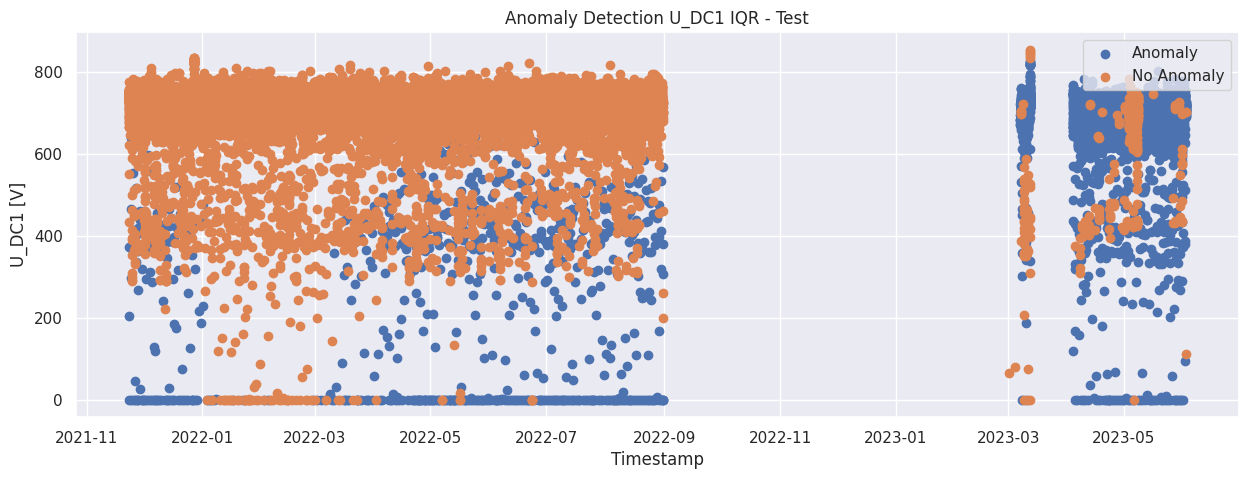

In [412]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_test['Timestamp'],no_anomaly_iqr_test['U_DC1'])
plt.scatter(anomaly_iqr_test['Timestamp'],anomaly_iqr_test['U_DC1'])
plt.xlabel('Timestamp')
plt.ylabel('U_DC1 [V]')
plt.title('Anomaly Detection U_DC1 IQR - Test')
plt.legend(['Anomaly','No Anomaly'])

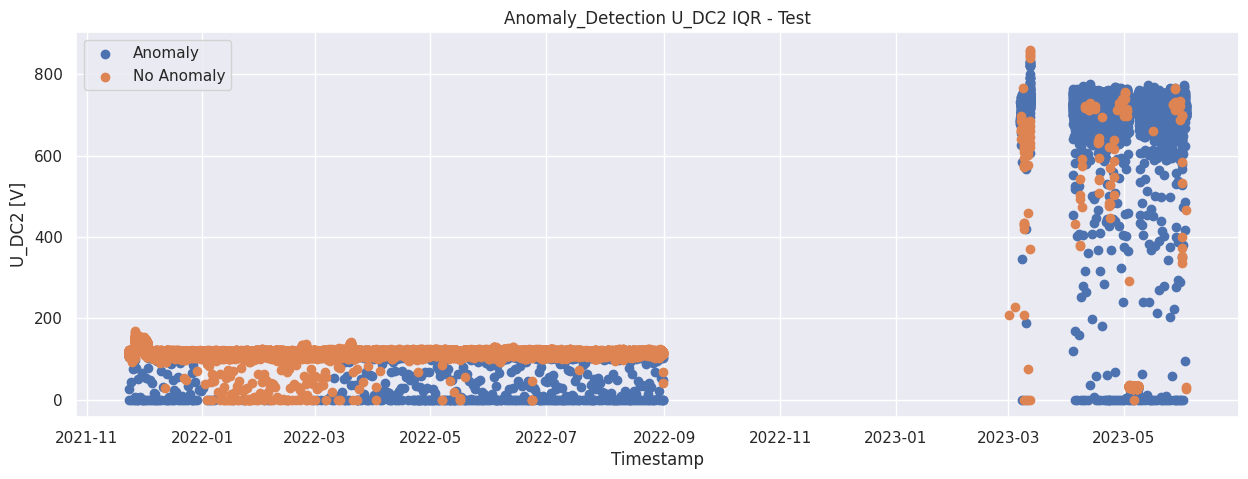

In [413]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_test['Timestamp'],no_anomaly_iqr_test['U_DC2'])
plt.scatter(anomaly_iqr_test['Timestamp'],anomaly_iqr_test['U_DC2'])
plt.xlabel('Timestamp')
plt.ylabel('U_DC2 [V]')
plt.title('Anomaly_Detection U_DC2 IQR - Test')
plt.legend(['Anomaly','No Anomaly'])

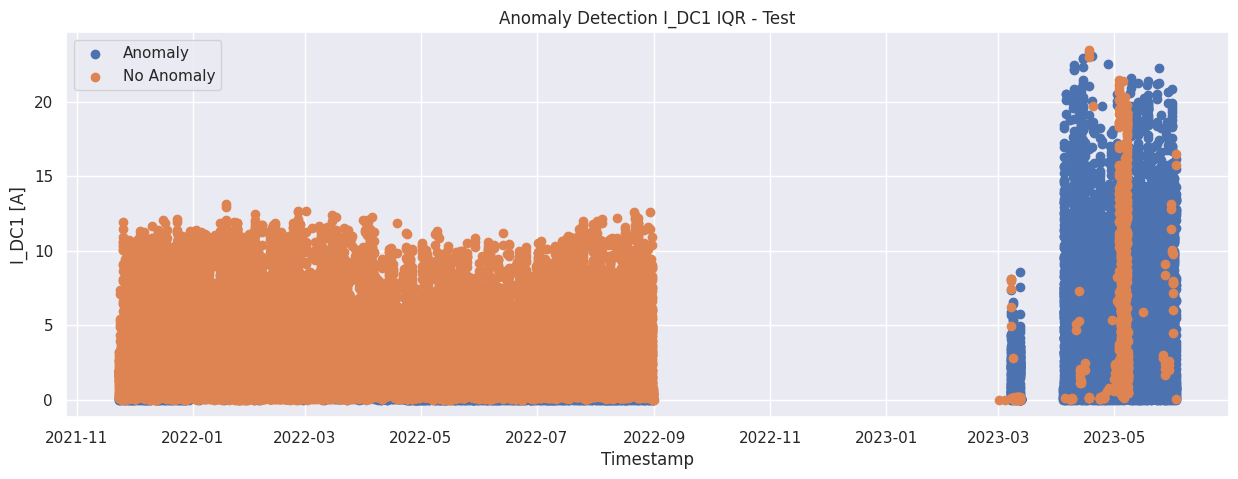

In [414]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_test['Timestamp'],no_anomaly_iqr_test['I_DC1'])
plt.scatter(anomaly_iqr_test['Timestamp'],anomaly_iqr_test['I_DC1'])
plt.xlabel('Timestamp')
plt.ylabel('I_DC1 [A]')
plt.title('Anomaly Detection I_DC1 IQR - Test')
plt.legend(['Anomaly','No Anomaly'])

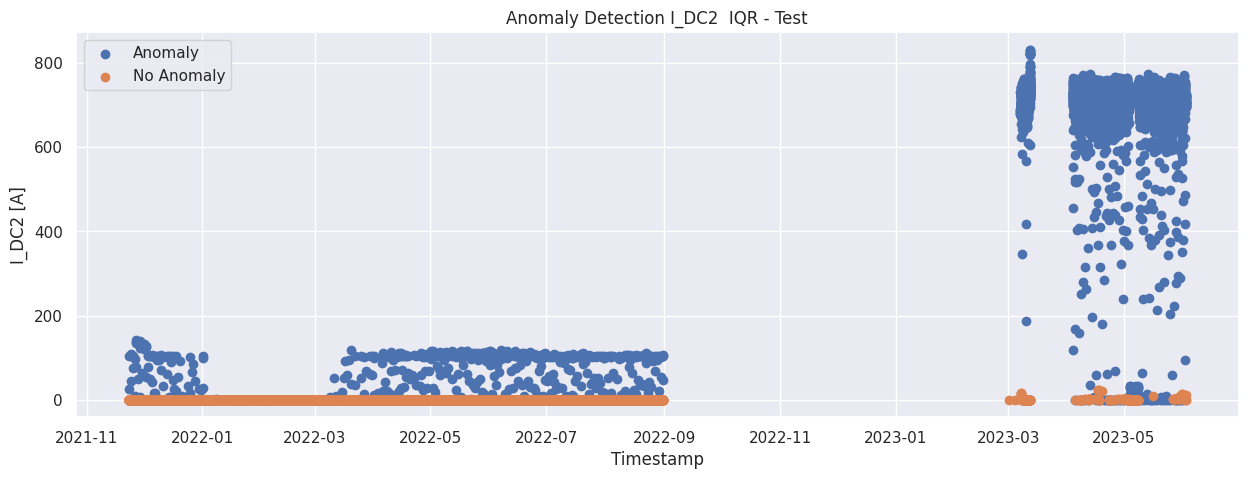

In [415]:
plt.figure(figsize=(15, 5))
plt.scatter(no_anomaly_iqr_test['Timestamp'],no_anomaly_iqr_test['U_DC2'])
plt.scatter(anomaly_iqr_test['Timestamp'],anomaly_iqr_test['I_DC2'])
plt.xlabel('Timestamp')
plt.ylabel('I_DC2 [A]')
plt.title('Anomaly Detection I_DC2  IQR - Test')
plt.legend(['Anomaly','No Anomaly'])

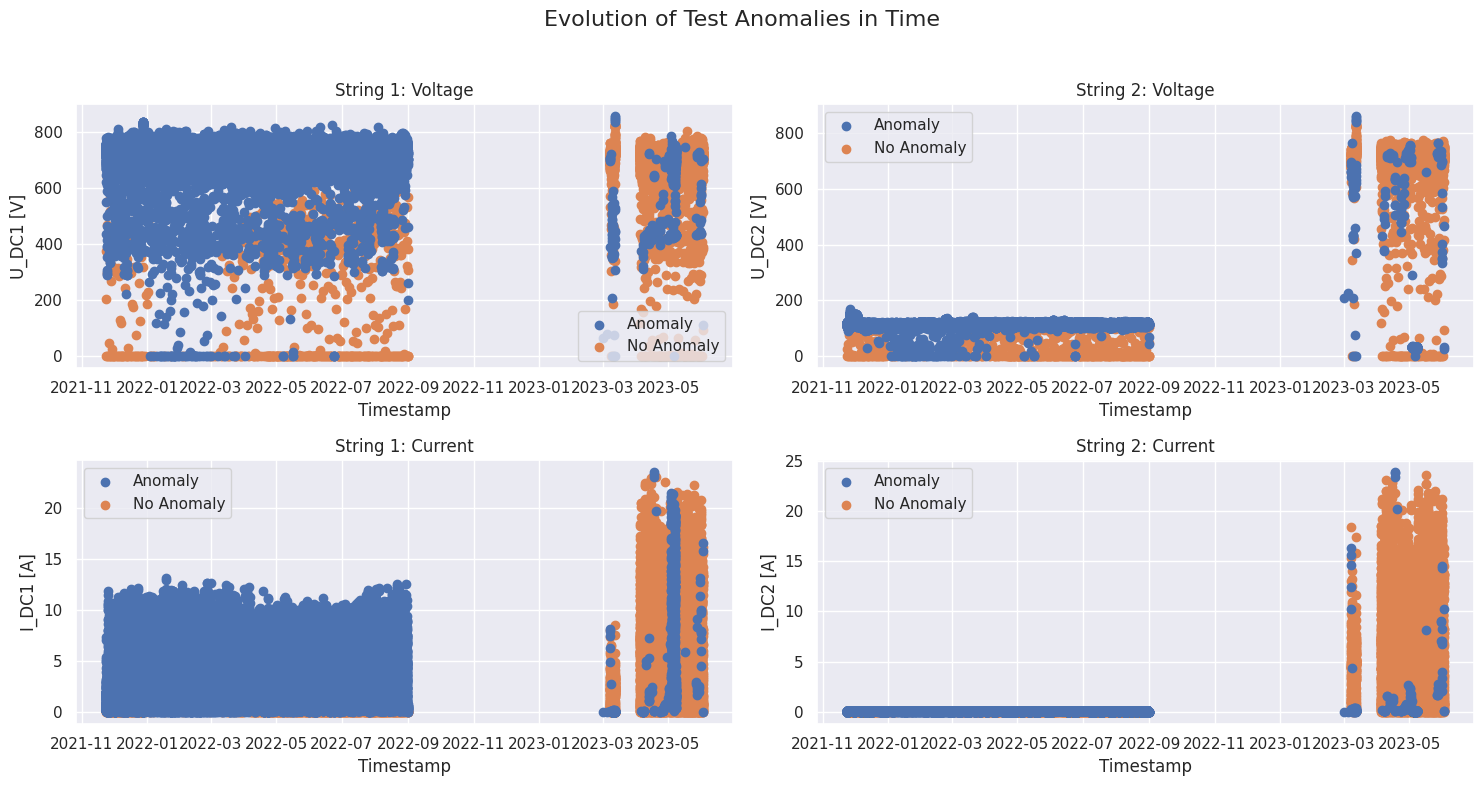

In [455]:
plt.figure(figsize=(15, 8))
plt.suptitle('Evolution of Test Anomalies in Time', fontsize=16)

# --- Subplot 1: Voltage String 1 (Top Left) ---
plt.subplot(2, 2, 1)
plt.scatter(anomaly_iqr_test['Timestamp'], anomaly_iqr_test['U_DC1'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_test['Timestamp'], no_anomaly_iqr_test['U_DC1'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('U_DC1 [V]')
plt.title('String 1: Voltage')
plt.legend()

# --- Subplot 2: Voltage String 2 (Top Right) ---
plt.subplot(2, 2, 2)
plt.scatter(anomaly_iqr_test['Timestamp'], anomaly_iqr_test['U_DC2'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_test['Timestamp'], no_anomaly_iqr_test['U_DC2'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('U_DC2 [V]')
plt.title('String 2: Voltage')
plt.legend()

# --- Subplot 3: Current String 1 (Bottom Left) ---
plt.subplot(2, 2, 3)
plt.scatter(anomaly_iqr_test['Timestamp'], anomaly_iqr_test['I_DC1'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_test['Timestamp'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('I_DC1 [A]')
plt.title('String 1: Current')
plt.legend()

# --- Subplot 4: Current String 2 (Bottom Right) ---
plt.subplot(2, 2, 4)
plt.scatter(anomaly_iqr_test['Timestamp'], anomaly_iqr_test['I_DC2'], label='Anomaly', color='C0', zorder=2)
plt.scatter(no_anomaly_iqr_test['Timestamp'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('Timestamp')
plt.ylabel('I_DC2 [A]')
plt.title('String 2: Current')
plt.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [360]:
statistical_anomaly_df = pd.concat([merged_df_train,merged_df_test])
statistical_anomaly_df = statistical_anomaly_df[['Timestamp','U_DC1','U_DC2','I_DC1','I_DC2','Anomaly']]

In [ ]:
#statistical_anomaly_df.to_csv('statistical_df_with_anomalies.csv', sep=';', index=False, encoding='utf-8')

## **MÉTODOS DE MACHINE LEARNING PARA DETECCIÓN DE ANOMALÍAS**



No supervisado

In [78]:
scaler = StandardScaler()

### *Método Isolation Forest*

In [79]:
df_if = filtered_data

time = df_if[['Timestamp']]
rows_if = df_if[['U_DC1','U_DC2','I_DC1','I_DC2']]

df_train_if = df_if[(df_if['Timestamp'] < '2021-09-03')]
df_test_if = df_if[(df_if['Timestamp'] >= '2021-09-03')]

scaled_df_if = scaler.fit_transform(rows_if)

x_train_if = scaled_df_if[0:102236]
x_test_if = scaled_df_if[102236:150398]

y_train_if = np.array(merged_df_train['Anomaly'])
y_train_if[y_train_if == 1] = -1
y_train_if[y_train_if == 0] = 1

y_test_if = np.array(merged_df_test['Anomaly'])
y_test_if[y_test_if == 1] = -1
y_test_if[y_test_if == 0] = 1

#### Datos de entrenamiento

In [ ]:
"""
from sklearn.metrics import accuracy_score, make_scorer, precision_score, recall_score, f1_score

isolation_forest = IsolationForest(random_state=42)

scoring_if = {"Accuracy": make_scorer(accuracy_score),
              "Precision": make_scorer(precision_score),
              "Recall": make_scorer(recall_score),
              "F1-Score": make_scorer(f1_score)}

param_grid_if = {'n_estimators': np.array((range(100, 800, 50))),
              'bootstrap': np.array([True, False]),
              'max_features': np.array([1,2,3,4])}

grid_dt_estimator_if = model_selection.GridSearchCV(isolation_forest,
                                                 param_grid_if,
                                                 scoring=scoring_if,
                                                 refit='Accuracy',
                                                 cv=5,
                                                 return_train_score=True)

grid_dt_estimator_if.fit(x_train_if, y_train_if)



print("Best parameters found:")
print(grid_dt_estimator_if.best_params_)
"""
#Best Parameters
#bootstrap: False
#n_estimators = 150
#contamination = 'auto'
#max_samples= 'auto'
#max_features=2

'\nfrom sklearn.metrics import accuracy_score, make_scorer, precision_score, recall_score, f1_score\n\nisolation_forest = IsolationForest(random_state=42)\n\nscoring_if = {"Accuracy": make_scorer(accuracy_score),\n              "Precision": make_scorer(precision_score),\n              "Recall": make_scorer(recall_score),\n              "F1-Score": make_scorer(f1_score)}\n\nparam_grid_if = {\'n_estimators\': np.array((range(100, 800, 50))),\n              \'bootstrap\': np.array([True, False]),\n              \'max_features\': np.array([1,2,3,4])}\n\ngrid_dt_estimator_if = model_selection.GridSearchCV(isolation_forest,\n                                                 param_grid_if,\n                                                 scoring=scoring_if,\n                                                 refit=\'Accuracy\',\n                                                 cv=5,\n                                                 return_train_score=True)\n\ngrid_dt_estimator_if.fit(x_train_if

In [81]:
best_if_model = IsolationForest(random_state=42, bootstrap=False, n_estimators=150, contamination='auto',max_samples='auto',max_features=2)
#Train model
best_if_model.fit(x_train_if)
pred_if_model_train = np.array(best_if_model.predict(x_train_if))
df_train_if['Anomaly'] = pred_if_model_train

/tmp/ipykernel_6487/2215008055.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_if['Anomaly'] = pred_if_model_train


In [82]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(pred_if_model_train,y_train_if)
precision = precision_score(pred_if_model_train,y_train_if)
f1_score = f1_score(pred_if_model_train,y_train_if)
recall = recall_score(pred_if_model_train,y_train_if)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.8770711422630914
Accuracy: 0.859775421573614
F1_Score: 0.9194642937396073
Recall: 0.9661637269485962


In [83]:
def compute_tp_tn_fn_fp(y_act, y_pred):
    tp = sum((y_act == -1) & (y_pred == -1))  # true anomalies
    tn = sum((y_act ==  1) & (y_pred ==  1))  # true normals
    fn = sum((y_act == -1) & (y_pred ==  1))  # missed anomalies
    fp = sum((y_act ==  1) & (y_pred == -1))  # false alarms
    return tp, tn, fn, fp

tp,tn,fn,fp = compute_tp_tn_fn_fp(y_train_if,pred_if_model_train)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 6064
Number of TN: 81836
Number of FP: 11470
Number of FN: 2866


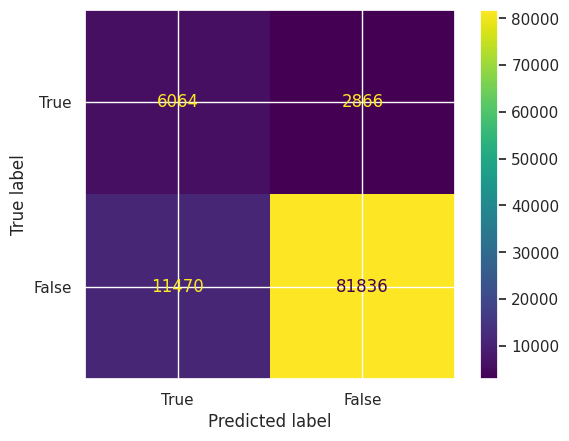

In [84]:
cm_train = confusion_matrix(y_train_if,pred_if_model_train)
cm_train_display = ConfusionMatrixDisplay(confusion_matrix = cm_train, display_labels = [True,False])
cm_train_display.plot()
plt.show()

In [85]:
count0 = (df_train_if['Anomaly'] == 1).sum()
count1 = (df_train_if['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

84702 17534


In [86]:
anomaly_if_train = df_train_if[df_train_if['Anomaly'] == -1]
no_anomaly_if_train = df_train_if[df_train_if['Anomaly'] == 1]

In [87]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_train['Timestamp'].isin(anomaly_if_train['Timestamp']).sum())

6064


/tmp/ipykernel_6487/2490782466.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_train['Timestamp'].isin(anomaly_if_train['Timestamp']).sum())


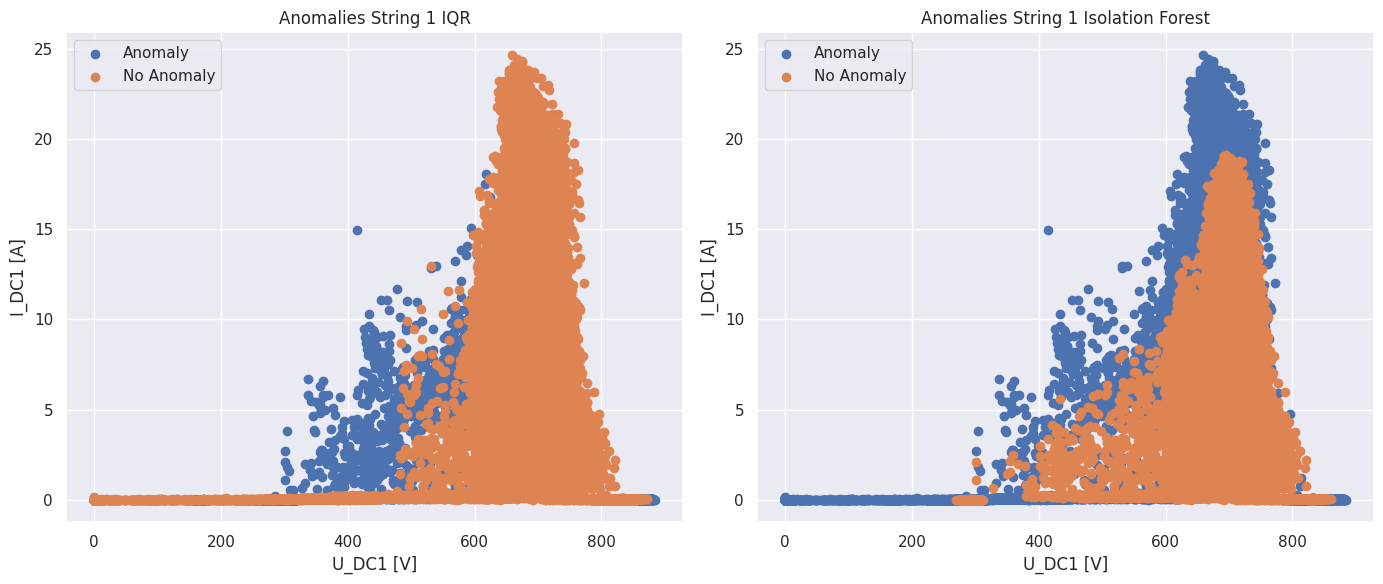

In [91]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14,6))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_if_train['U_DC1'], anomaly_if_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_if_train['U_DC1'], no_anomaly_if_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Isolation Forest')


# Ajustes de diseño
plt.tight_layout()
plt.show()

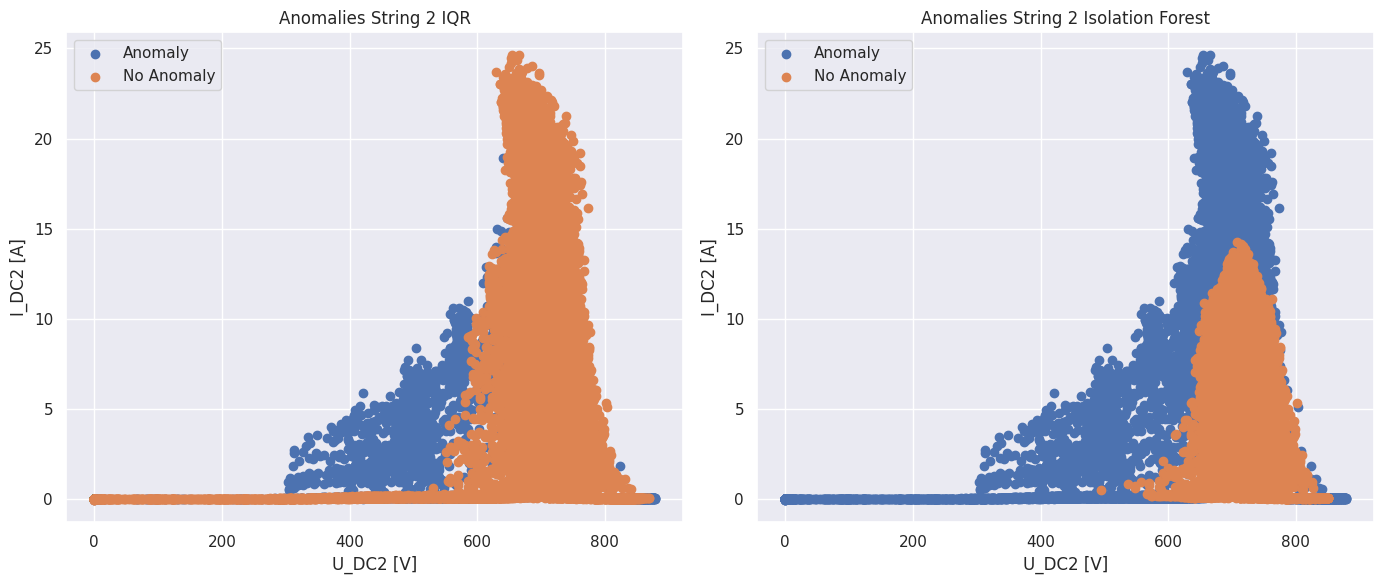

In [92]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 6))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_if_train['U_DC2'], anomaly_if_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_if_train['U_DC2'], no_anomaly_if_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Isolation Forest')


# Ajustes de diseño
plt.tight_layout()
plt.show()

#### Datos de Prueba

In [93]:
pred_if_model_test = np.array(best_if_model.predict(x_test_if))
df_test_if['Anomaly'] = pred_if_model_test

/tmp/ipykernel_6487/2604629069.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_if['Anomaly'] = pred_if_model_test


In [94]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_test_if,pred_if_model_test)
precision = precision_score(y_test_if,pred_if_model_test)
f1_score = f1_score(y_test_if,pred_if_model_test)
recall = recall_score(y_test_if,pred_if_model_test)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9941333333333333
Accuracy: 0.9629791121631162
F1_Score: 0.8932015573525007
Recall: 0.8108754758020663


In [95]:
tp,tn,fn,fp = compute_tp_tn_fn_fp(y_test_if,pred_if_model_test)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 38923
Number of TN: 7456
Number of FP: 1739
Number of FN: 44


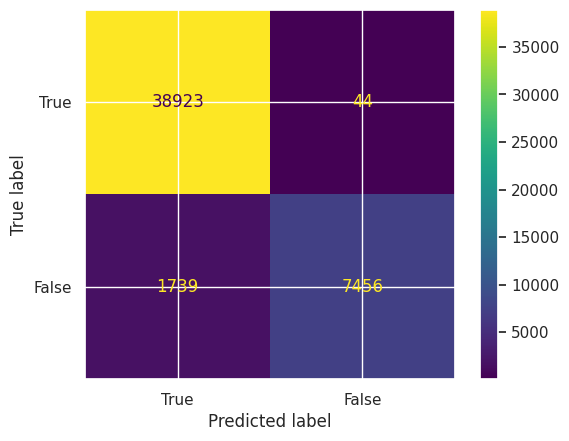

In [96]:
cm_test = confusion_matrix(y_test_if,pred_if_model_test)
cm_train_display = ConfusionMatrixDisplay(confusion_matrix = cm_test, display_labels = [True,False])
cm_train_display.plot()
plt.show()

In [97]:
count0 = (df_test_if['Anomaly'] == 1).sum()
count1 = (df_test_if['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

7500 40662


In [98]:
anomaly_if_test = df_test_if[df_test_if['Anomaly'] == -1]
no_anomaly_if_test = df_test_if[df_test_if['Anomaly'] == 1]

In [99]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_test['Timestamp'].isin(anomaly_if_test['Timestamp']).sum())

38923


/tmp/ipykernel_6487/2029141275.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_test['Timestamp'].isin(anomaly_if_test['Timestamp']).sum())


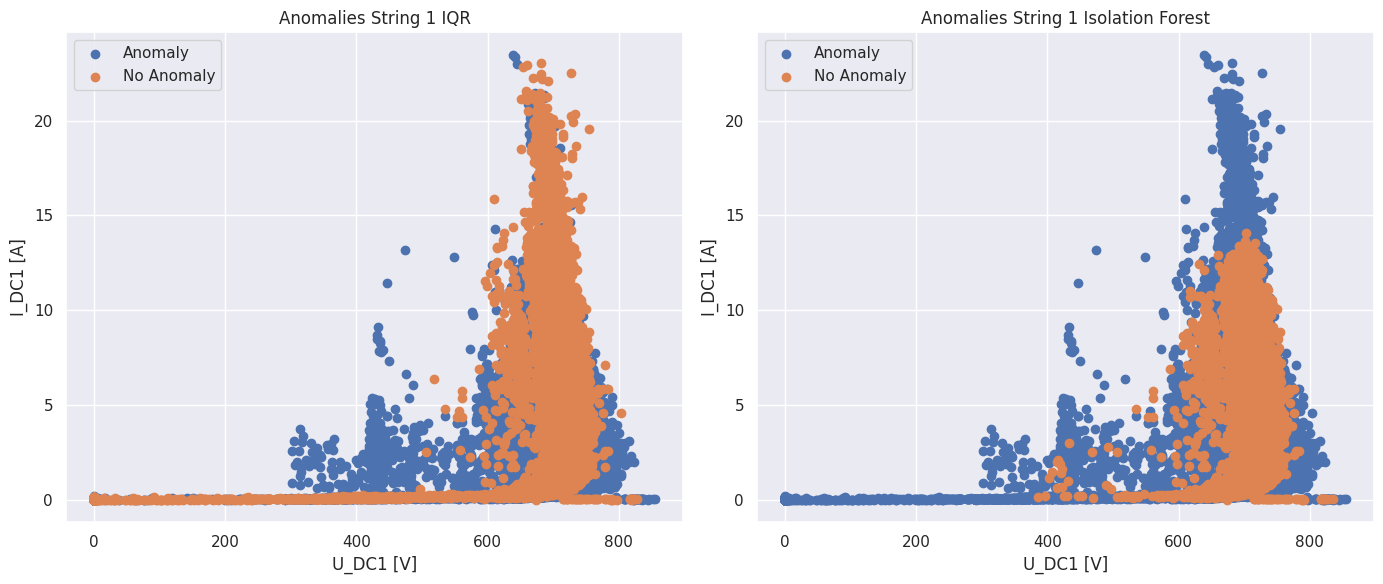

In [100]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 6))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_if_test['U_DC1'], anomaly_if_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_if_test['U_DC1'], no_anomaly_if_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Isolation Forest')


# Ajustes de diseño
plt.tight_layout()
plt.show()

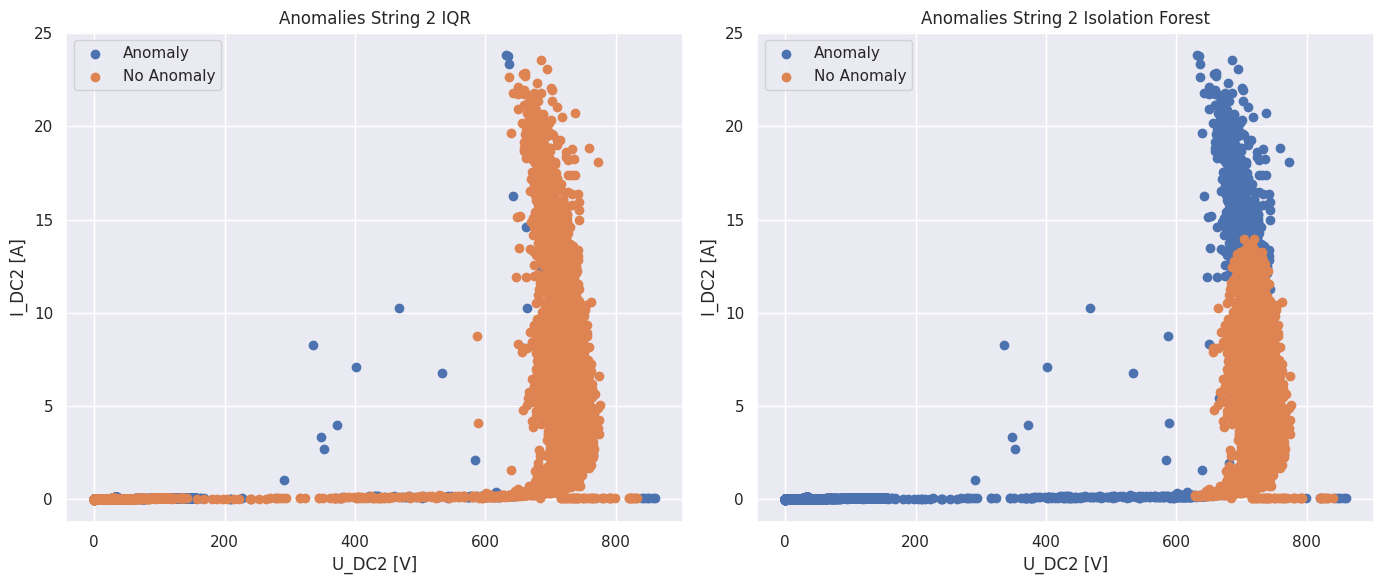

In [101]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 6))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_if_test['U_DC2'], anomaly_if_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_if_test['U_DC2'], no_anomaly_if_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Isolation Forest')


# Ajustes de diseño
plt.tight_layout()
plt.show()

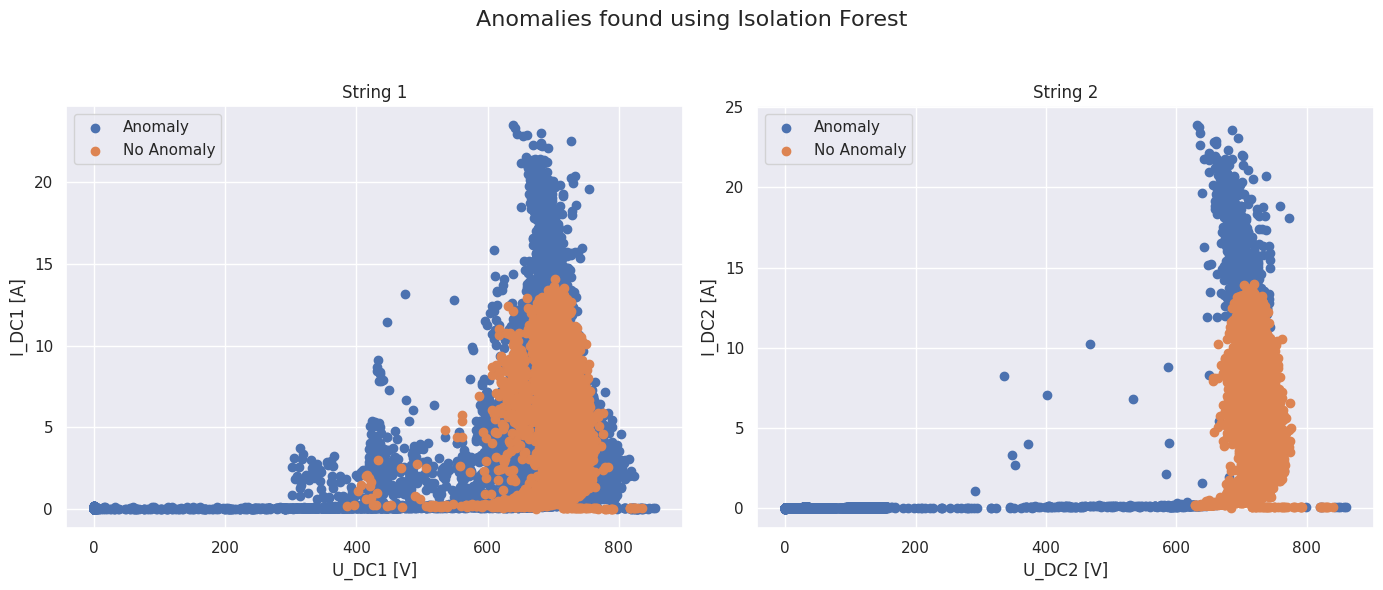

In [185]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle (Super Title) for the overarching figure title
plt.suptitle("Anomaly detection using Isolation Forest", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
plt.scatter(anomaly_if_test['U_DC1'], anomaly_if_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_if_test['U_DC1'], no_anomaly_if_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
plt.scatter(anomaly_if_test['U_DC2'], anomaly_if_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_if_test['U_DC2'], no_anomaly_if_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping (rect parameter ensures it doesn't clip the suptitle)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### *Método One-Class-SVM*

In [231]:
df_oc_svm = filtered_data

time = df_oc_svm[['Timestamp']]
rows_oc_svm = df_oc_svm[['U_DC1','U_DC2','I_DC1','I_DC2']]

df_train_oc_svm = df_oc_svm[(df_oc_svm['Timestamp'] < '2021-09-03')]
df_test_oc_svm = df_oc_svm[(df_oc_svm['Timestamp'] >= '2021-09-03')]

#scaler_gpu = cpp.StandardScaler()
scaled_df_oc_svm = scaler.fit_transform(rows_oc_svm)

x_train_oc_svm = scaled_df_oc_svm[0:102236]
x_test_oc_svm = scaled_df_oc_svm[102236:150398]

y_train_oc_svm = merged_df_train['Anomaly']
y_train_oc_svm[y_train_oc_svm == 1] = -1
y_train_oc_svm[y_train_oc_svm == 0] = 1

y_test_oc_svm = merged_df_test['Anomaly']
y_test_oc_svm[y_test_oc_svm == 1] = -1
y_test_oc_svm[y_test_oc_svm == 0] = 1

/tmp/ipykernel_6487/2730161181.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_train_oc_svm[y_train_oc_svm == 1] = -1
/tmp/ipykernel_6487/2730161181.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_train_oc_svm[y_train_oc_svm == 0] = 1
/tmp/ipykernel_6487/2730161181.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_test_oc_svm[y_test_oc_svm == 1] = -1
/tmp/ipykernel_6487/2730161181.py:21: SettingWithCopyWarning: 
A va

#### Datos de entrenamiento

In [ ]:
"""
#One-Class SVM
svm_model = cuml.

param_grid_svm = {'nu': np.array(np.arange(0.01,1,0.01)),
                  'kernel': np.array(['linear', 'poly', 'rbf', 'sigmoid']),
                  'gamma': np.array(['scale', 'auto'])}


grid_svm_estimator = cuml.model_selection.GridSearchCV(svm_model,
                                                  param_grid_svm,
                                                  scoring='accuracy',
                                                  cv=5)

grid_svm_estimator.fit(x_train_oc_svm, y_train_oc_svm)


print("Best parameters found for One Class-SVM:")
print(grid_svm_estimator.best_params_)
"""
#Best Parameters Found
#gamma: auto
#kernel: rbf
#nu = 0.01

'\n#One-Class SVM\nsvm_model = cuml.\n\nparam_grid_svm = {\'nu\': np.array(np.arange(0.01,1,0.01)),\n                  \'kernel\': np.array([\'linear\', \'poly\', \'rbf\', \'sigmoid\']),\n                  \'gamma\': np.array([\'scale\', \'auto\'])}\n\n\ngrid_svm_estimator = cuml.model_selection.GridSearchCV(svm_model,\n                                                  param_grid_svm,\n                                                  scoring=\'accuracy\',\n                                                  cv=5)\n\ngrid_svm_estimator.fit(x_train_oc_svm, y_train_oc_svm)\n\n\nprint("Best parameters found for One Class-SVM:")\nprint(grid_svm_estimator.best_params_)\n'

In [232]:
best_svm_model = OneClassSVM(nu=0.01,kernel='rbf',gamma='auto')
best_svm_model.fit(x_train_oc_svm)
pred_oc_svm_model_train = np.array(best_svm_model.predict(x_train_oc_svm))
df_train_oc_svm['Anomaly'] = pred_oc_svm_model_train

/tmp/ipykernel_6487/626667024.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_oc_svm['Anomaly'] = pred_oc_svm_model_train


In [233]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_train_oc_svm, pred_oc_svm_model_train)
precision = precision_score(y_train_oc_svm, pred_oc_svm_model_train)
f1_score = f1_score(y_train_oc_svm, pred_oc_svm_model_train)
recall = recall_score(y_train_oc_svm, pred_oc_svm_model_train)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9162577625953973
Accuracy: 0.9121346688055089
F1_Score: 0.9538369828308315
Recall: 0.994630570381326


In [234]:
def compute_tp_tn_fn_fp(y_act, y_pred):
    tp = sum((y_act == -1) & (y_pred == -1))  # true anomalies
    tn = sum((y_act ==  1) & (y_pred ==  1))  # true normals
    fn = sum((y_act == -1) & (y_pred ==  1))  # missed anomalies
    fp = sum((y_act ==  1) & (y_pred == -1))  # false alarms
    return tp, tn, fn, fp

tp,tn,fn,fp = compute_tp_tn_fn_fp(y_train_oc_svm, pred_oc_svm_model_train)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 448
Number of TN: 92805
Number of FP: 501
Number of FN: 8482


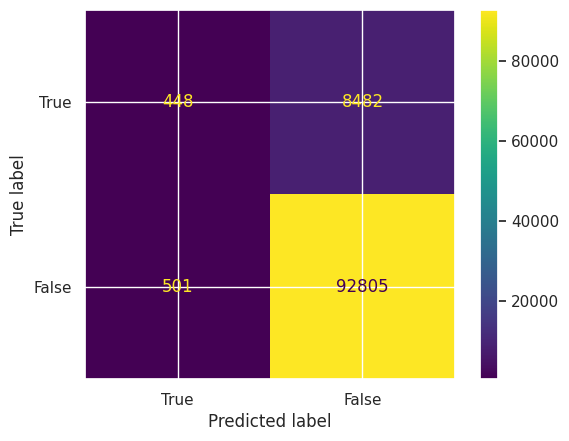

In [235]:
cm_train = confusion_matrix(y_train_oc_svm, pred_oc_svm_model_train)
cm_train_display = ConfusionMatrixDisplay(confusion_matrix = cm_train, display_labels = [True,False])
cm_train_display.plot()
plt.show()

In [236]:
count0 = (df_train_oc_svm['Anomaly'] == 1).sum()
count1 = (df_train_oc_svm['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

101287 949


In [237]:
anomaly_oc_svm_train = df_train_oc_svm[df_train_oc_svm['Anomaly'] == -1]
no_anomaly_oc_svm_train = df_train_oc_svm[df_train_oc_svm['Anomaly'] == 1]

In [238]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_train['Timestamp'].isin(anomaly_oc_svm_train['Timestamp']).sum())

448


/tmp/ipykernel_6487/2002706769.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_train['Timestamp'].isin(anomaly_oc_svm_train['Timestamp']).sum())


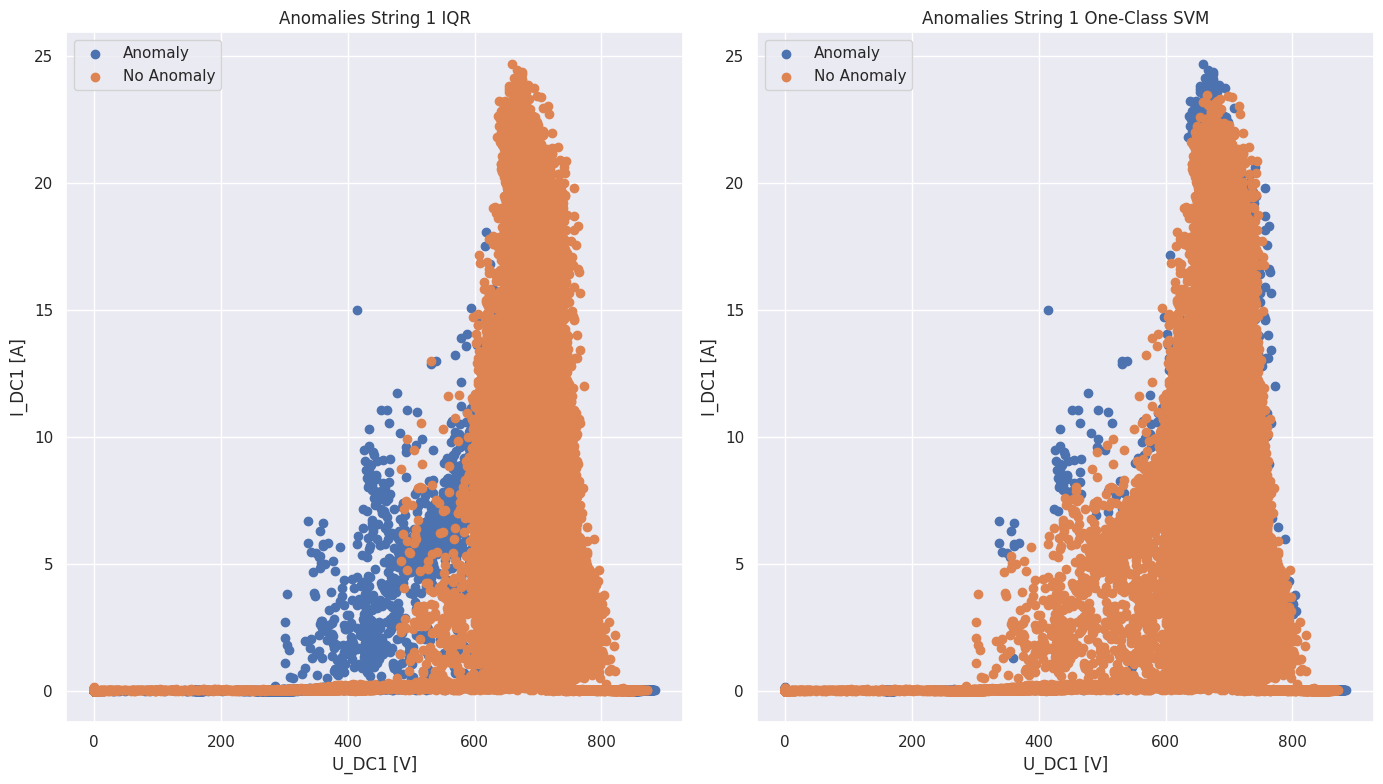

In [239]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_oc_svm_train['U_DC1'], anomaly_oc_svm_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_oc_svm_train['U_DC1'], no_anomaly_oc_svm_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 One-Class SVM')


# Ajustes de diseño
plt.tight_layout()
plt.show()

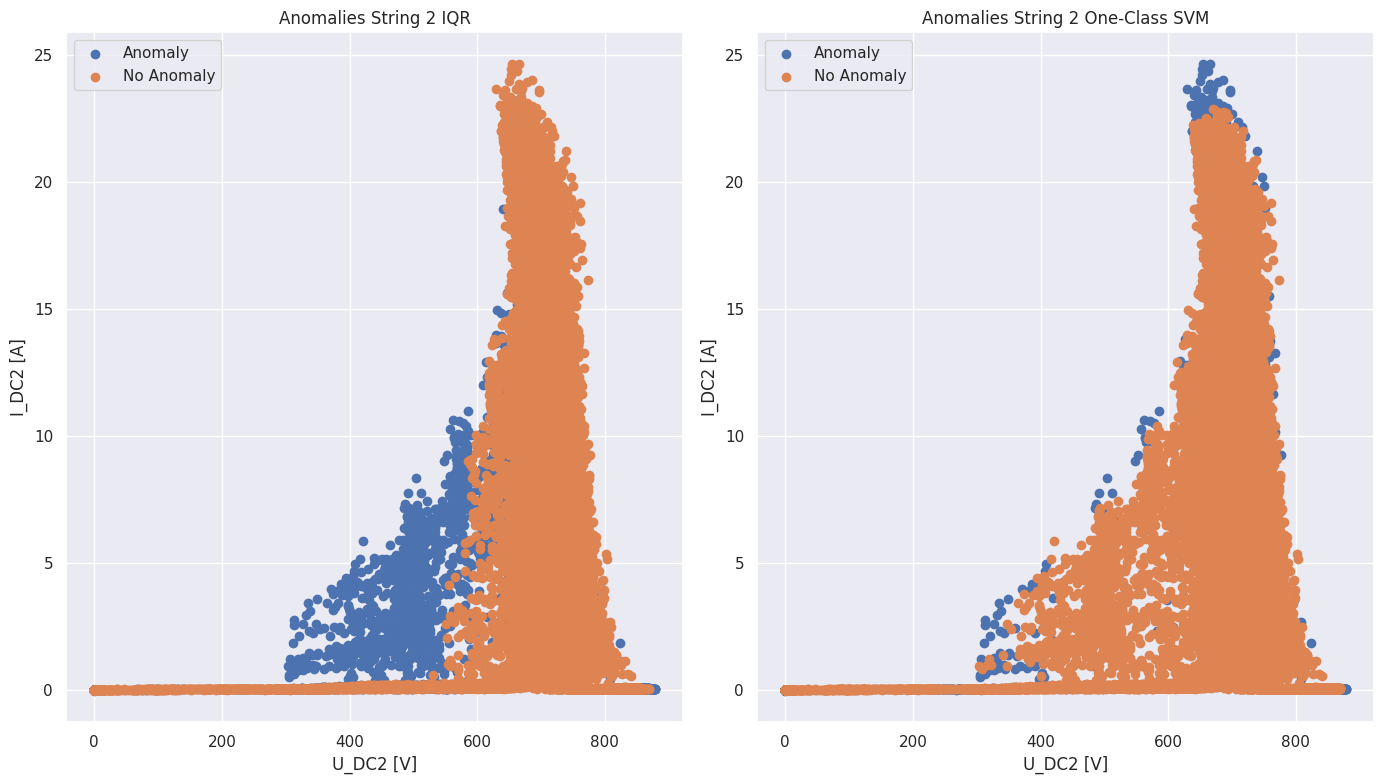

In [240]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_oc_svm_train['U_DC2'], anomaly_oc_svm_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_oc_svm_train['U_DC2'], no_anomaly_oc_svm_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 One-Class SVM')


# Ajustes de diseño
plt.tight_layout()
plt.show()

#### Datos de Prueba

In [241]:
pred_oc_svm_model_test = np.array(best_svm_model.predict(x_test_oc_svm))
df_test_oc_svm['Anomaly'] = pred_oc_svm_model_test

/tmp/ipykernel_6487/2902919663.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_oc_svm['Anomaly'] = pred_oc_svm_model_test


In [242]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_test_oc_svm,pred_oc_svm_model_test)
precision = precision_score(y_test_oc_svm,pred_oc_svm_model_test)
f1_score = f1_score(y_test_oc_svm,pred_oc_svm_model_test)
recall = recall_score(y_test_oc_svm,pred_oc_svm_model_test)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9811495316294668
Accuracy: 0.9818529130850048
F1_Score: 0.9510144602623024
Recall: 0.9226753670473083


In [243]:
tp,tn,fn,fp = compute_tp_tn_fn_fp(y_test_oc_svm,pred_oc_svm_model_test)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 38804
Number of TN: 8484
Number of FP: 711
Number of FN: 163


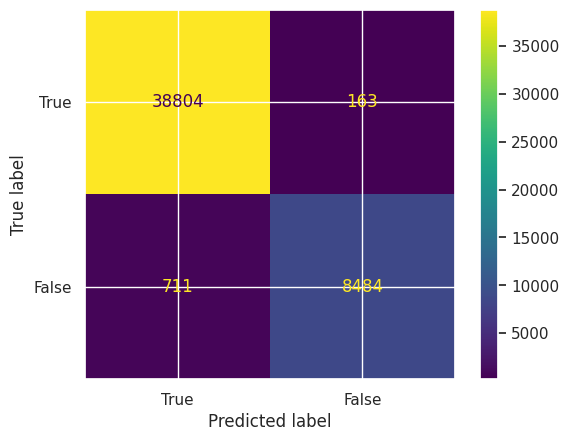

In [244]:
cm_test = confusion_matrix(y_test_oc_svm,pred_oc_svm_model_test)
cm_train_display = ConfusionMatrixDisplay(confusion_matrix = cm_test, display_labels = [True,False])
cm_train_display.plot()
plt.show()

In [245]:
count0 = (df_test_oc_svm['Anomaly'] == 1).sum()
count1 = (df_test_oc_svm['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

8647 39515


In [246]:
anomaly_oc_svm_test = df_test_oc_svm[df_test_oc_svm['Anomaly'] == -1]
no_anomaly_oc_svm_test = df_test_oc_svm[df_test_oc_svm['Anomaly'] == 1]

In [247]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_test['Timestamp'].isin(anomaly_oc_svm_test['Timestamp']).sum())

38804


/tmp/ipykernel_6487/244550466.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_test['Timestamp'].isin(anomaly_oc_svm_test['Timestamp']).sum())


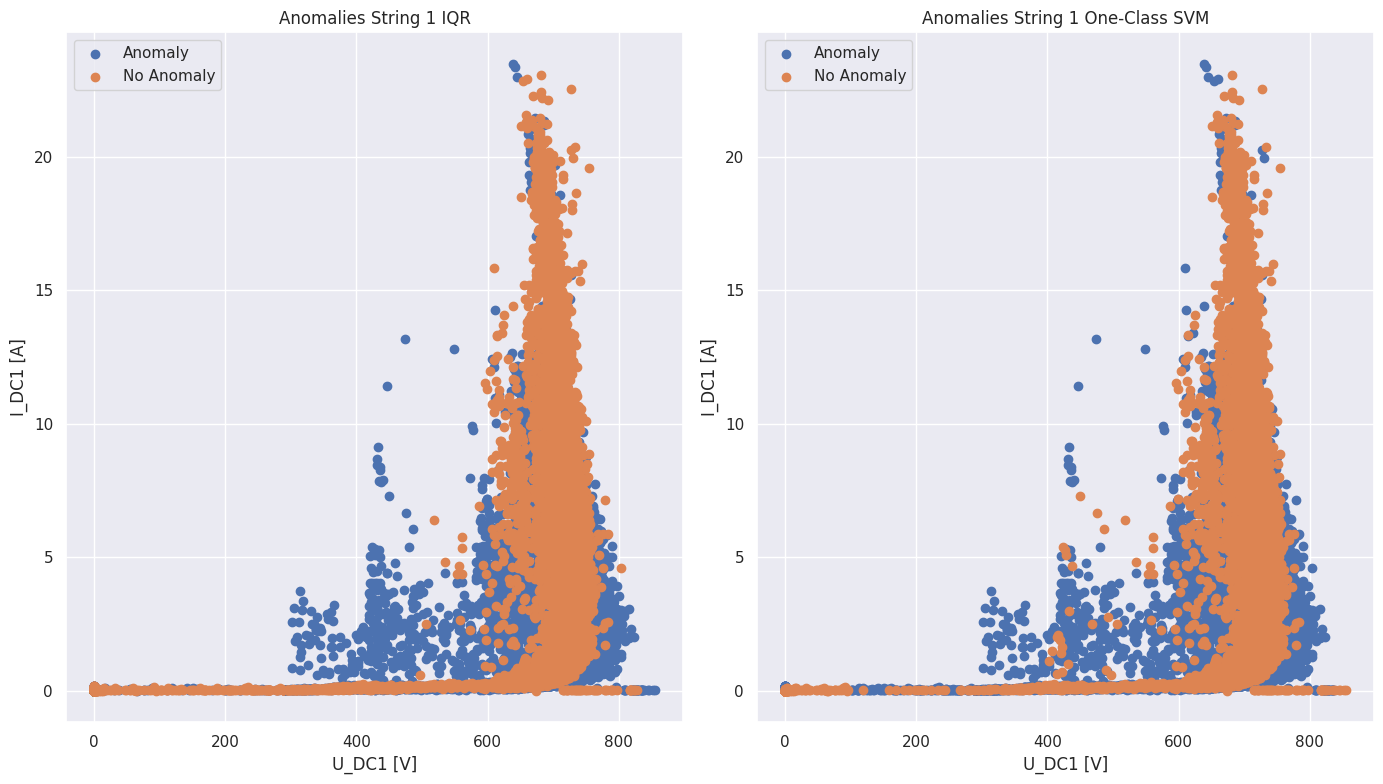

In [248]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_oc_svm_test['U_DC1'], anomaly_oc_svm_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_oc_svm_test['U_DC1'], no_anomaly_oc_svm_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 One-Class SVM')


# Ajustes de diseño
plt.tight_layout()
plt.show()

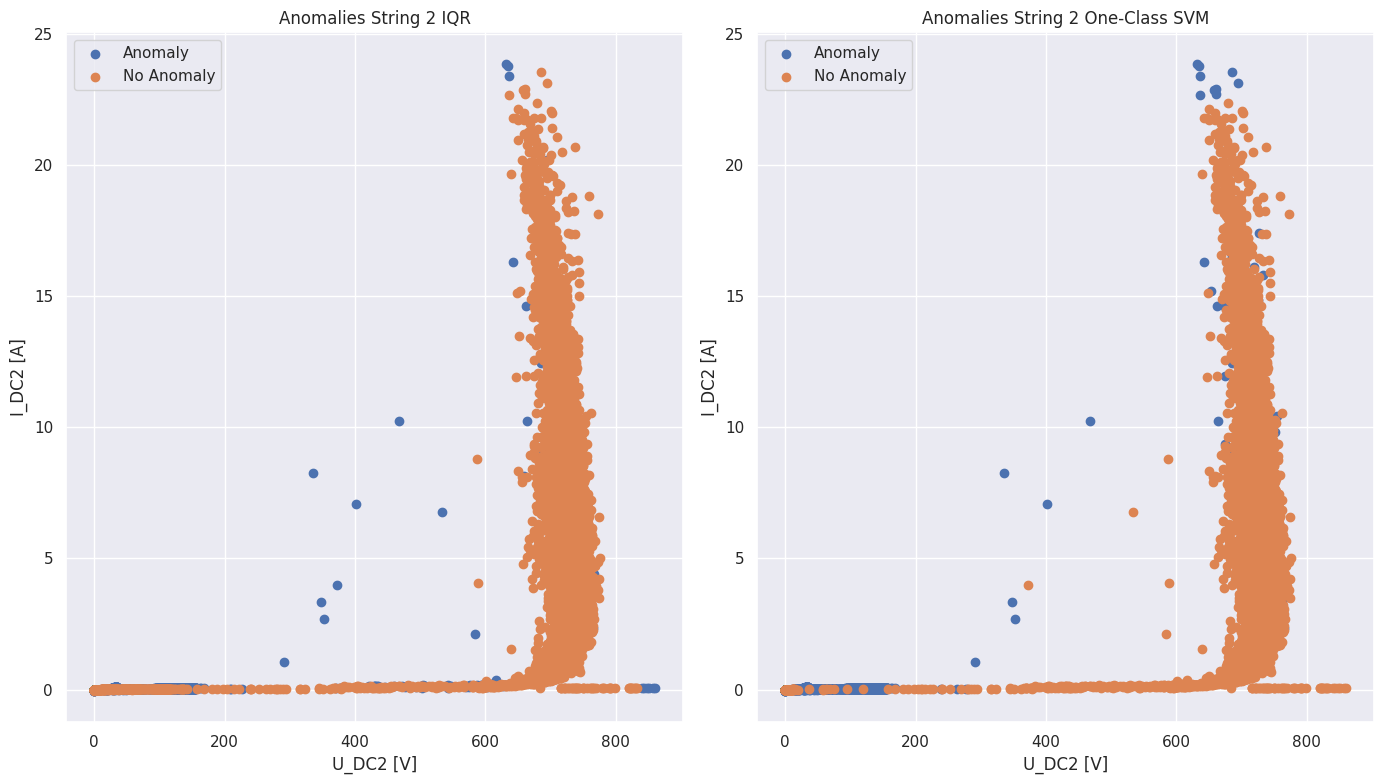

In [249]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_oc_svm_test['U_DC2'], anomaly_oc_svm_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_oc_svm_test['U_DC2'], no_anomaly_oc_svm_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 One-Class SVM')


# Ajustes de diseño
plt.tight_layout()
plt.show()

In [250]:
df_train_oc_svm['Anomaly'] = df_train_oc_svm['Anomaly'].replace({1: 0, -1: 1})
df_test_oc_svm['Anomaly'] = df_test_oc_svm['Anomaly'].replace({1: 0, -1: 1})


/tmp/ipykernel_6487/1477221402.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_oc_svm['Anomaly'] = df_train_oc_svm['Anomaly'].replace({1: 0, -1: 1})
/tmp/ipykernel_6487/1477221402.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_oc_svm['Anomaly'] = df_test_oc_svm['Anomaly'].replace({1: 0, -1: 1})


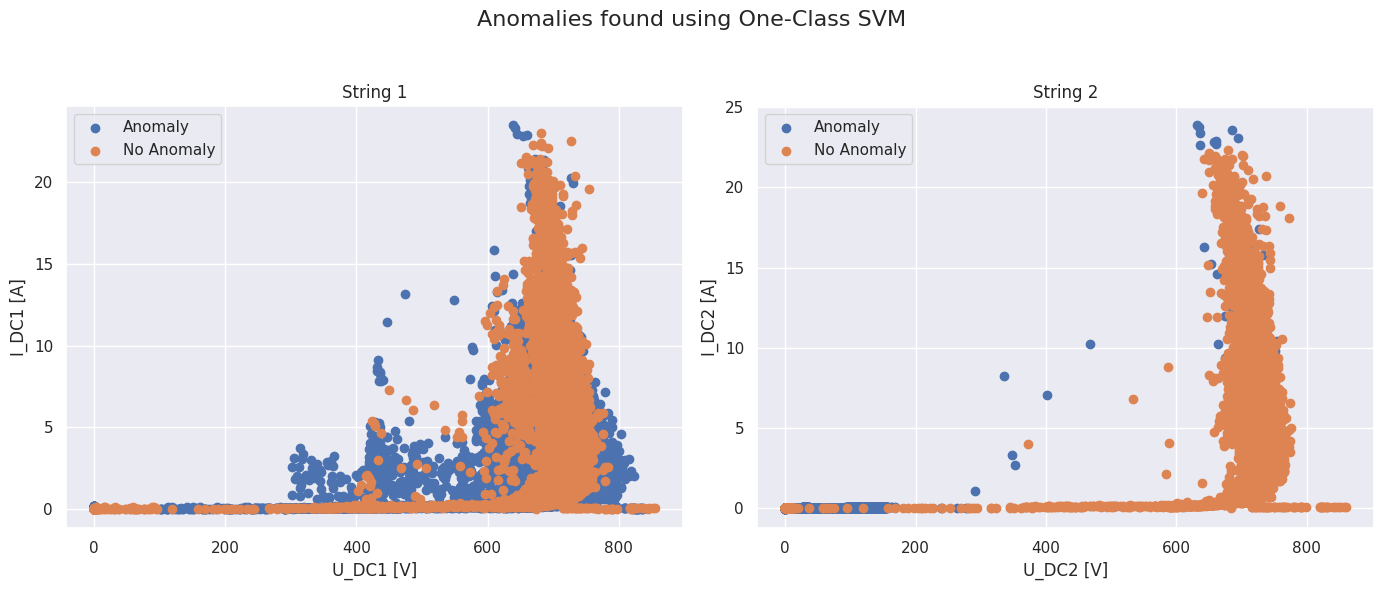

In [251]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle for the overarching figure title
plt.suptitle("Anomalies found using One-Class SVM", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
plt.scatter(anomaly_oc_svm_test['U_DC1'], anomaly_oc_svm_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_oc_svm_test['U_DC1'], no_anomaly_oc_svm_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
plt.scatter(anomaly_oc_svm_test['U_DC2'], anomaly_oc_svm_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_oc_svm_test['U_DC2'], no_anomaly_oc_svm_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping and render to screen
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
ml_anomaly_df = pd.concat([df_train_oc_svm, df_test_oc_svm])

In [ ]:
ml_anomaly_df.to_csv('df_with_anomalies_oc_svm.csv', sep=';', index=False, encoding='utf-8')

### *Método Local Outlier Factor*

In [293]:
df_lof = filtered_data

time = df_lof[['Timestamp']]
rows_lof = df_lof[['U_DC1','U_DC2','I_DC1','I_DC2']]

df_train_lof = df_lof[(df_lof['Timestamp'] < '2021-09-03')]
df_test_lof = df_lof[(df_lof['Timestamp'] >= '2021-09-03')]

scaled_df_lof = scaler.fit_transform(rows_lof)

x_train_lof = scaled_df_lof[0:102236]
x_test_lof = scaled_df_lof[102236:150398]

In [294]:
y_train_lof = np.array(merged_df_train['Anomaly'])

In [295]:
np.unique(y_train_lof)

array([0, 1])

In [296]:
y_train_lof[y_train_lof == 1] = -1
y_train_lof[y_train_lof == 0] = 1

In [297]:
y_test_lof = np.array(merged_df_test['Anomaly'])
y_test_lof[y_test_lof == 1] = -1
y_test_lof[y_test_lof == 0] = 1

In [298]:
np.unique(y_test_lof)

array([-1,  1])

In [299]:
y_train_lof

array([1, 1, 1, ..., 1, 1, 1], shape=(102236,))

In [300]:
np.count_nonzero(y_train_lof == -1)

np.int64(8930)

In [301]:
np.count_nonzero(y_train_lof == 1)

np.int64(93306)

#### Datos de entrenamiento

In [ ]:
"""
lof_model = LocalOutlierFactor(novelty=True)



param_grid_lof = {'n_neighbors': np.arange(5,50,5)}

grid_lof_estimator = model_selection.GridSearchCV(lof_model,
                                                  param_grid_lof,
                                                  scoring='accuracy',
                                                  cv=5,
                                                  n_jobs=-1)

grid_lof_estimator.fit(x_train_lof, y_train_lof)


print("Best parameters found in Isolation Forest:")
print(grid_lof_estimator.best_params_)
"""
#Best parameters
#n_neighbors=10

'\nlof_model = LocalOutlierFactor(novelty=True)\n\n\n\nparam_grid_lof = {\'n_neighbors\': np.arange(5,50,5)}\n\ngrid_lof_estimator = model_selection.GridSearchCV(lof_model,\n                                                  param_grid_lof,\n                                                  scoring=\'accuracy\',\n                                                  cv=5,\n                                                  n_jobs=-1)\n\ngrid_lof_estimator.fit(x_train_lof, y_train_lof)\n\n\nprint("Best parameters found in Isolation Forest:")\nprint(grid_lof_estimator.best_params_)\n'

In [302]:
best_lof = LocalOutlierFactor(n_neighbors=10,contamination='auto',novelty=True)
best_lof.fit(x_train_lof)
pred_lof_model_train = np.array(best_lof.predict(x_train_lof))
df_train_lof['Anomaly'] = pred_lof_model_train

/tmp/ipykernel_6487/1224201537.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_lof['Anomaly'] = pred_lof_model_train


In [303]:
np.unique(pred_lof_model_train)

array([-1,  1])

In [304]:
np.unique(y_train_lof)

array([-1,  1])

In [305]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_train_lof, pred_lof_model_train)
precision = precision_score(y_train_lof, pred_lof_model_train)
f1_score = f1_score(y_train_lof, pred_lof_model_train)
recall = recall_score(y_train_lof, pred_lof_model_train)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9139235207940921
Accuracy: 0.8998493681286436
F1_Score: 0.9471254395885297
Recall: 0.9828306861295093


In [306]:
tp,tn,fn,fp = compute_tp_tn_fn_fp(y_train_lof, pred_lof_model_train)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 293
Number of TN: 91704
Number of FP: 1602
Number of FN: 8637


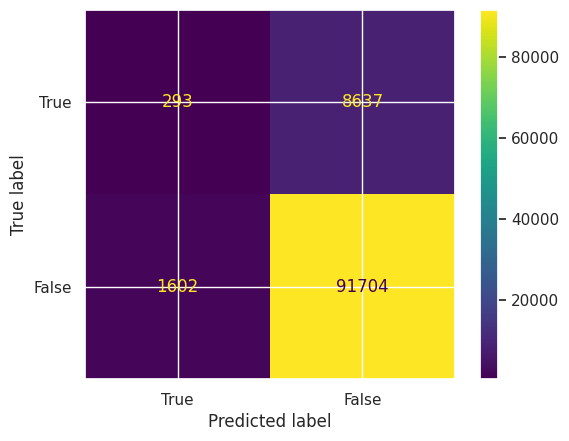

In [307]:
cm_train = confusion_matrix(y_train_lof, pred_lof_model_train)
cm_train_display = ConfusionMatrixDisplay(confusion_matrix = cm_train, display_labels = [True,False])
cm_train_display.plot()
plt.show()

In [308]:
count0 = (df_train_lof['Anomaly'] == 1).sum()
count1 = (df_train_lof['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

100341 1895


In [309]:
anomaly_lof_train = df_train_lof[df_train_lof['Anomaly'] == -1]
no_anomaly_lof_train = df_train_lof[df_train_lof['Anomaly'] == 1]

In [310]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_train['Timestamp'].isin(anomaly_lof_train['Timestamp']).sum())

293


/tmp/ipykernel_6487/4272679109.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_train['Timestamp'].isin(anomaly_lof_train['Timestamp']).sum())


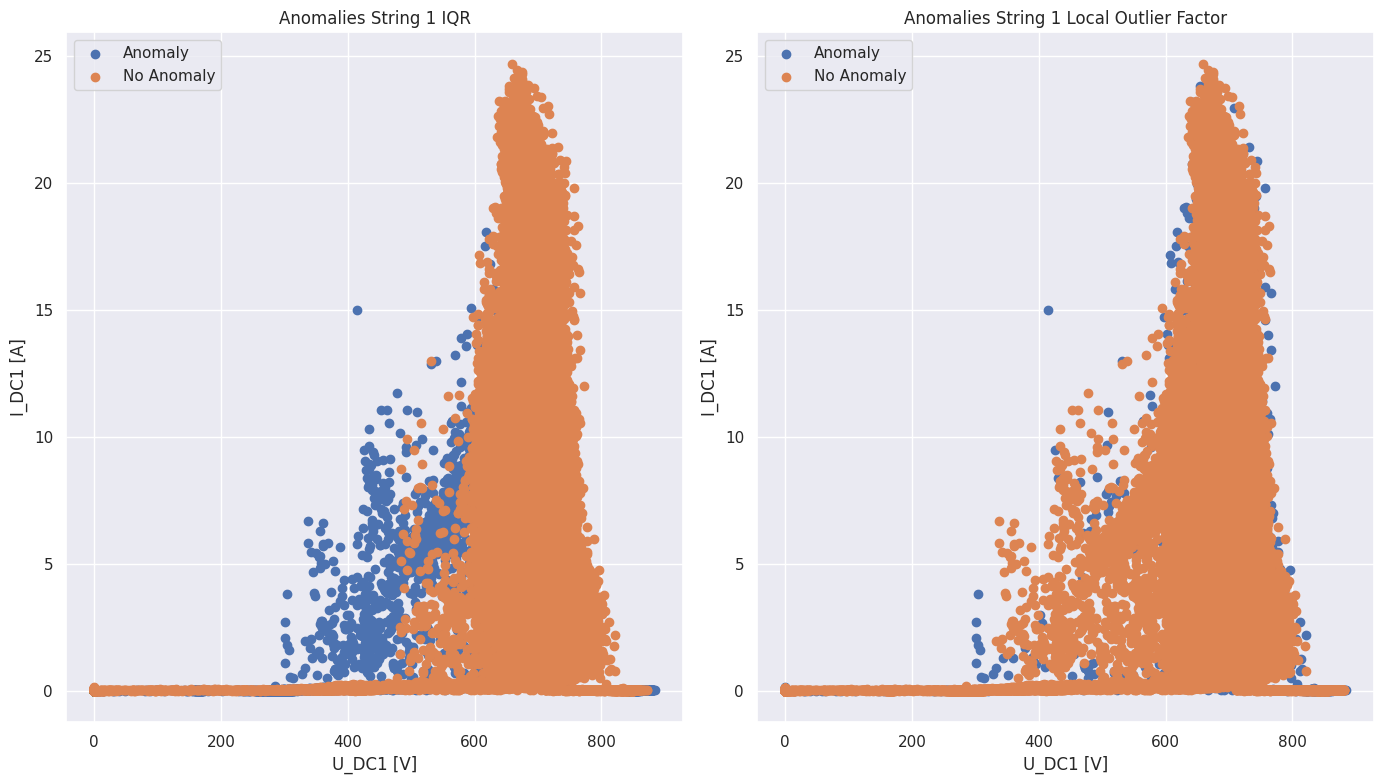

In [311]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_lof_train['U_DC1'], anomaly_lof_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_lof_train['U_DC1'], no_anomaly_lof_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Local Outlier Factor')


# Ajustes de diseño
plt.tight_layout()
plt.show()

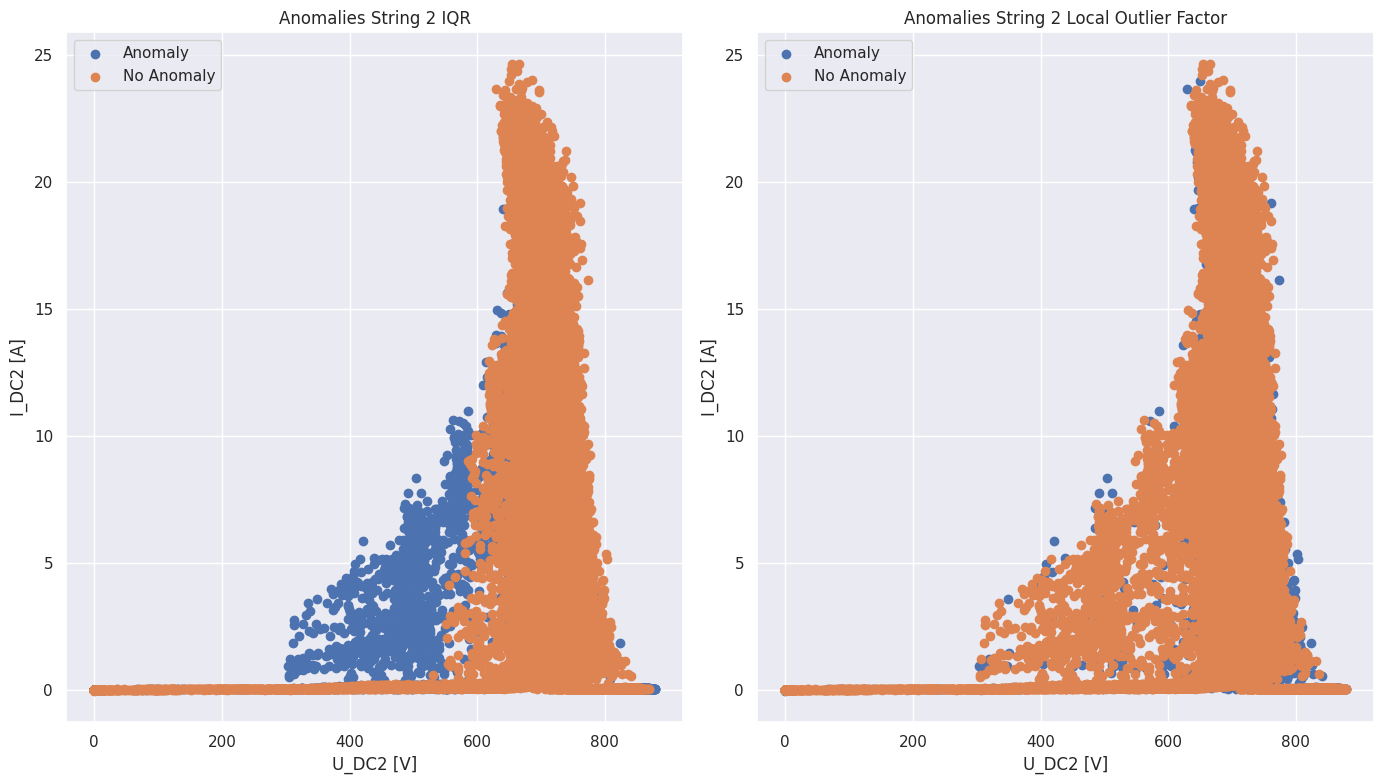

In [312]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_lof_train['U_DC2'], anomaly_lof_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_lof_train['U_DC2'], no_anomaly_lof_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Local Outlier Factor')


# Ajustes de diseño
plt.tight_layout()
plt.show()

#### Datos de prueba

In [313]:
pred_lof_model_test = np.array(best_lof.predict(x_test_lof))
df_test_lof['Anomaly'] = pred_lof_model_test

/tmp/ipykernel_6487/2450283303.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_lof['Anomaly'] = pred_lof_model_test


In [314]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_test_lof, pred_lof_model_test)
precision = precision_score(y_test_lof, pred_lof_model_test)
f1_score = f1_score(y_test_lof, pred_lof_model_test)
recall = recall_score(y_test_lof, pred_lof_model_test)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9791666666666666
Accuracy: 0.970495411320128
F1_Score: 0.9178944935575201
Recall: 0.8638390429581294


In [315]:
tp,tn,fn,fp = compute_tp_tn_fn_fp(y_test_lof, pred_lof_model_test)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 38798
Number of TN: 7943
Number of FP: 1252
Number of FN: 169


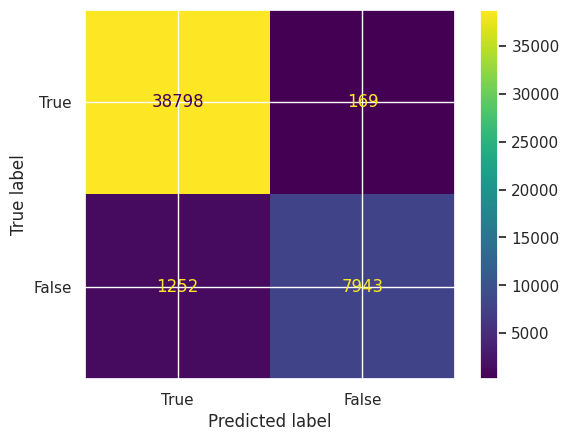

In [316]:
cm_test = confusion_matrix(y_test_lof, pred_lof_model_test)
cm_train_display = ConfusionMatrixDisplay(confusion_matrix = cm_test, display_labels = [True,False])
cm_train_display.plot()
plt.show()

In [317]:
count0 = (df_test_lof['Anomaly'] == 1).sum()
count1 = (df_test_lof['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

8112 40050


In [318]:
anomaly_lof_test = df_test_lof[df_test_lof['Anomaly'] == -1]
no_anomaly_lof_test = df_test_lof[df_test_lof['Anomaly'] == 1]

#### Graficas

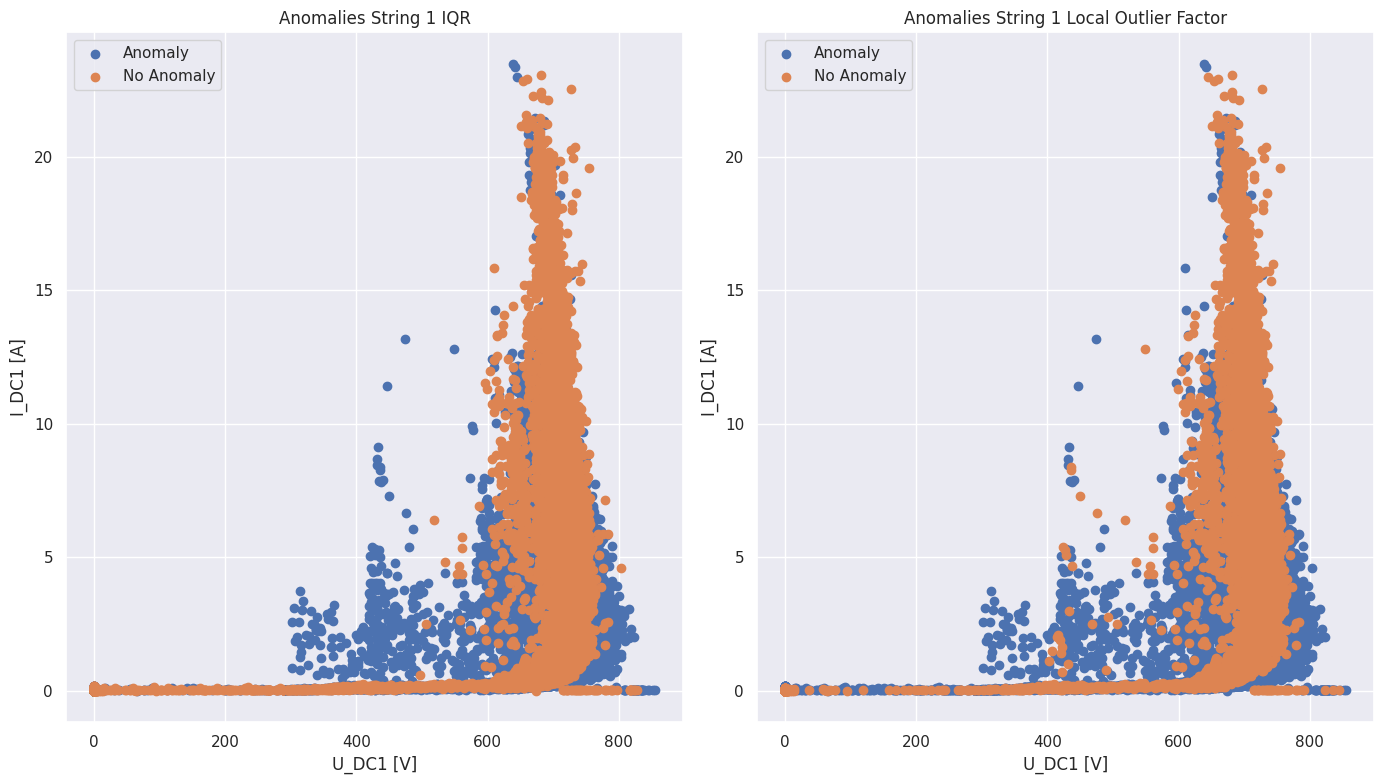

In [ ]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_lof_test['U_DC1'], anomaly_lof_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_lof_test['U_DC1'], no_anomaly_lof_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Local Outlier Factor')


# Ajustes de diseño
plt.tight_layout()
plt.show()

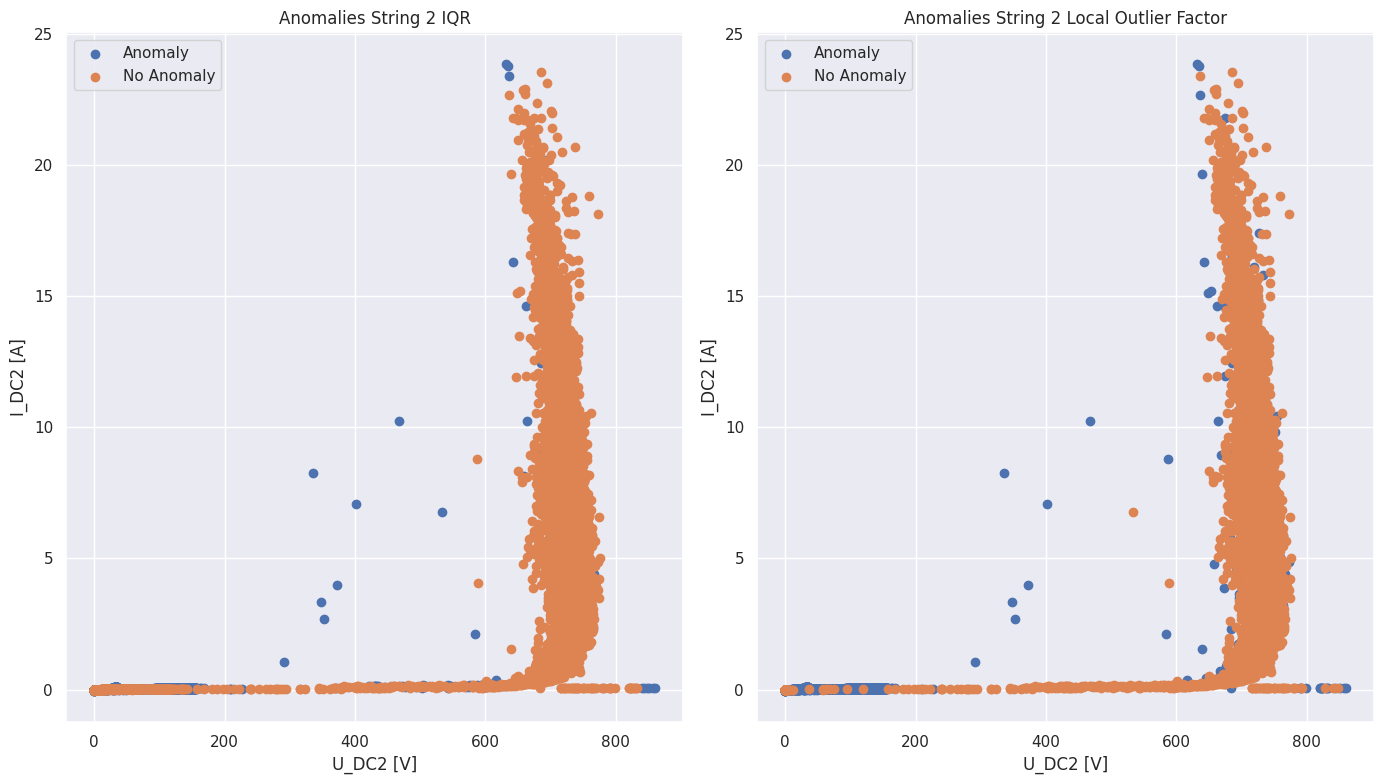

In [ ]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_lof_test['U_DC2'], anomaly_lof_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_lof_test['U_DC2'], no_anomaly_lof_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Local Outlier Factor')


# Ajustes de diseño
plt.tight_layout()
plt.show()

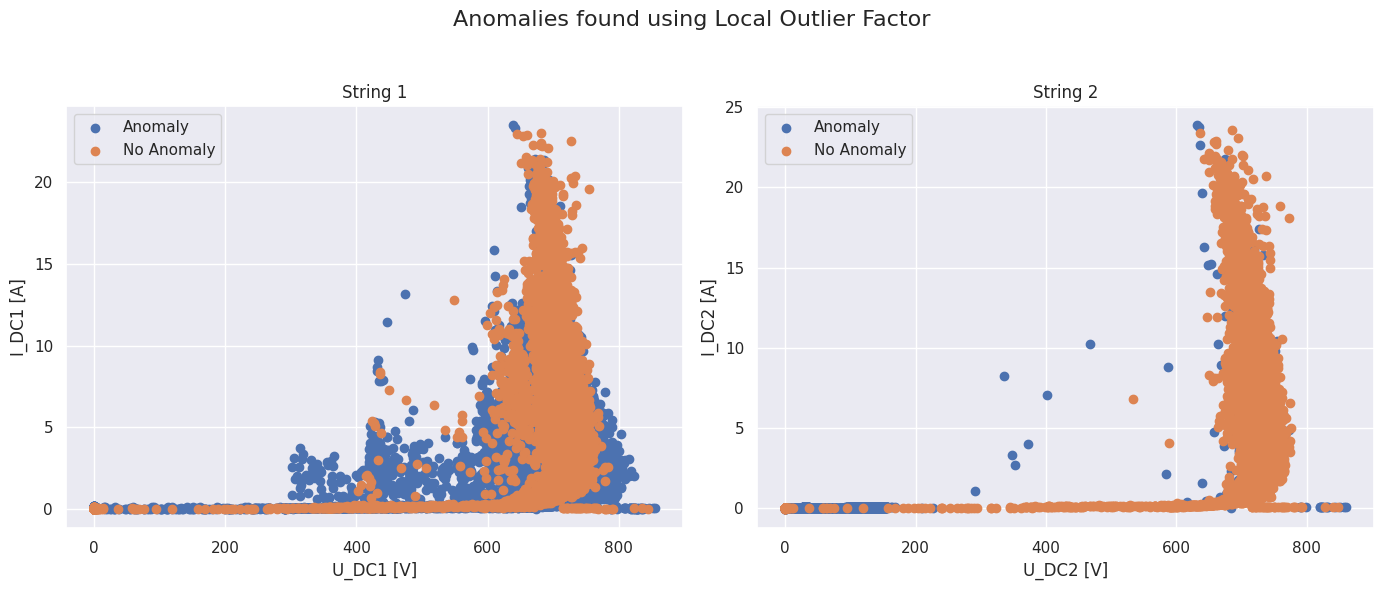

In [319]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle for the overarching figure title
plt.suptitle("Anomalies found using Local Outlier Factor", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
plt.scatter(anomaly_lof_test['U_DC1'], anomaly_lof_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_lof_test['U_DC1'], no_anomaly_lof_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
plt.scatter(anomaly_lof_test['U_DC2'], anomaly_lof_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_lof_test['U_DC2'], no_anomaly_lof_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping and render to screen
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### *Método Robust Covariance*

In [416]:
df_rc = filtered_data

time = df_rc[['Timestamp']]
rows_rc = df_rc[['U_DC1','U_DC2','I_DC1','I_DC2']]

df_train_rc = df_rc[(df_rc['Timestamp'] < '2021-09-03')]
df_test_rc = df_rc[(df_rc['Timestamp'] >= '2021-09-03')]

scaled_df_rc = scaler.fit_transform(rows_rc)

x_train_rc = scaled_df_rc[0:102236]
x_test_rc = scaled_df_rc[102236:150398]

In [417]:
y_train_rc = merged_df_train['Anomaly']
y_train_rc[y_train_rc == 1] = -1
y_train_rc[y_train_rc == 0] = 1

/tmp/ipykernel_6487/2494461339.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_train_rc[y_train_rc == 1] = -1
/tmp/ipykernel_6487/2494461339.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_train_rc[y_train_rc == 0] = 1


In [418]:
y_test_rc = merged_df_test['Anomaly']
y_test_rc[y_test_rc == 1] = -1
y_test_rc[y_test_rc == 0] = 1

/tmp/ipykernel_6487/1442226839.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_test_rc[y_test_rc == 1] = -1
/tmp/ipykernel_6487/1442226839.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_test_rc[y_test_rc == 0] = 1


In [419]:
np.unique(y_test_rc)

array([-1,  1])

In [420]:
np.unique(y_train_rc)

array([-1,  1])

Datos de entrenamiento

In [ ]:
"""
rc = EllipticEnvelope(random_state=42)

scoring_rc = {
    "Accuracy":  make_scorer(accuracy_score),
    "Precision": make_scorer(precision_score, pos_label=-1, zero_division=0),
    "Recall":    make_scorer(recall_score,    pos_label=-1, zero_division=0),
    "F1-Score":  make_scorer(f1_score,        pos_label=-1, zero_division=0),
}

param_grid_rc = {
    "contamination":    np.array([0.005, 0.01, 0.02]),
    "support_fraction": np.array([None, 0.6, 0.7, 0.8, 0.9]),
    "assume_centered":  np.array([False,True]),
}
"""

'\nrc = EllipticEnvelope(random_state=42)\n\nscoring_rc = {\n    "Accuracy":  make_scorer(accuracy_score),\n    "Precision": make_scorer(precision_score, pos_label=-1, zero_division=0),\n    "Recall":    make_scorer(recall_score,    pos_label=-1, zero_division=0),\n    "F1-Score":  make_scorer(f1_score,        pos_label=-1, zero_division=0),\n}\n\nparam_grid_rc = {\n    "contamination":    np.array([0.005, 0.01, 0.02]),\n    "support_fraction": np.array([None, 0.6, 0.7, 0.8, 0.9]),\n    "assume_centered":  np.array([False,True]),\n}\n'

In [ ]:
"""
REFIT_METRIC = "Accuracy"

grid_rc = model_selection.GridSearchCV(
    estimator=rc,
    param_grid=param_grid_rc,
    scoring=scoring_rc,
    refit=REFIT_METRIC,
    cv=5,
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

# 2.1) Fit grid on TRAIN only (unsupervised fit; y used only for scoring)
grid_rc.fit(x_train_rc, y_train_rc)

print("Best parameters found (EllipticEnvelope):")
print(grid_rc.best_params_)

#Best Parameters
#assume_centered: False
#contamination: 0.005
#support_fraction: 0.9
"""


'\nREFIT_METRIC = "Accuracy"\n\ngrid_rc = model_selection.GridSearchCV(\n    estimator=rc,\n    param_grid=param_grid_rc,\n    scoring=scoring_rc,\n    refit=REFIT_METRIC,\n    cv=5,\n    n_jobs=-1,\n    return_train_score=True,\n    verbose=1\n)\n\n# 2.1) Fit grid on TRAIN only (unsupervised fit; y used only for scoring)\ngrid_rc.fit(x_train_rc, y_train_rc)\n\nprint("Best parameters found (EllipticEnvelope):")\nprint(grid_rc.best_params_)\n\n#Best Parameters\n#assume_centered: False\n#contamination: 0.005\n#support_fraction: 0.9\n'

In [421]:
best_model_rc = EllipticEnvelope(assume_centered=False, contamination=0.005, support_fraction=0.9,random_state=42)
best_model_rc.fit(x_train_rc)

EllipticEnvelope(contamination=0.005, random_state=42, support_fraction=0.9)

In [422]:
pred_rc_model_train = best_model_rc.predict(x_train_rc)
df_train_rc['Anomaly'] = pred_rc_model_train

/tmp/ipykernel_6487/1970263257.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_rc['Anomaly'] = pred_rc_model_train


In [423]:
np.unique(pred_rc_model_train)

array([-1,  1])

In [424]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_train_rc, pred_rc_model_train)
precision = precision_score(y_train_rc, pred_rc_model_train)
f1_score = f1_score(y_train_rc, pred_rc_model_train)
recall = recall_score(y_train_rc, pred_rc_model_train)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9172466674531085
Accuracy: 0.9176610978520287
F1_Score: 0.9568374096292878
Recall: 1.0


In [425]:
def compute_tp_tn_fn_fp(y_act, y_pred):
    tp = sum((y_act == -1) & (y_pred == -1))  # true anomalies
    tn = sum((y_act ==  1) & (y_pred ==  1))  # true normals
    fn = sum((y_act == -1) & (y_pred ==  1))  # missed anomalies
    fp = sum((y_act ==  1) & (y_pred == -1))  # false alarms
    return tp, tn, fn, fp


tp,tn,fn,fp = compute_tp_tn_fn_fp(y_train_rc, pred_rc_model_train)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 512
Number of TN: 93306
Number of FP: 0
Number of FN: 8418


In [426]:
count0 = (df_train_rc['Anomaly'] == 1).sum()
count1 = (df_train_rc['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

101724 512


In [427]:
anomaly_rc_train = df_train_rc[df_train_rc['Anomaly'] == -1]
no_anomaly_rc_train = df_train_rc[df_train_rc['Anomaly'] == 1]

In [428]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_train['Timestamp'].isin(anomaly_rc_train['Timestamp']).sum())

512


/tmp/ipykernel_6487/3373176866.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_train['Timestamp'].isin(anomaly_rc_train['Timestamp']).sum())


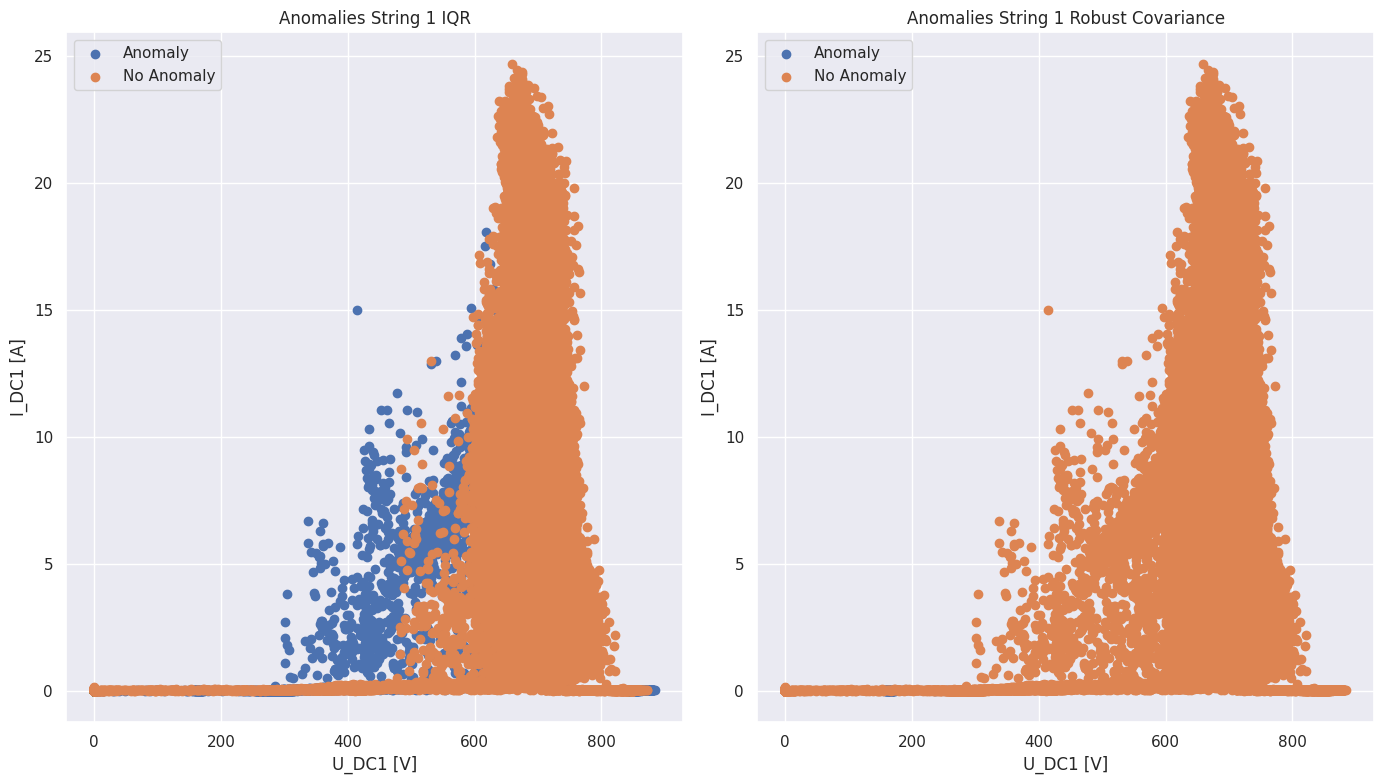

In [429]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_rc_train['U_DC1'], anomaly_rc_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_rc_train['U_DC1'], no_anomaly_rc_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Robust Covariance')


# Ajustes de diseño
plt.tight_layout()
plt.show()

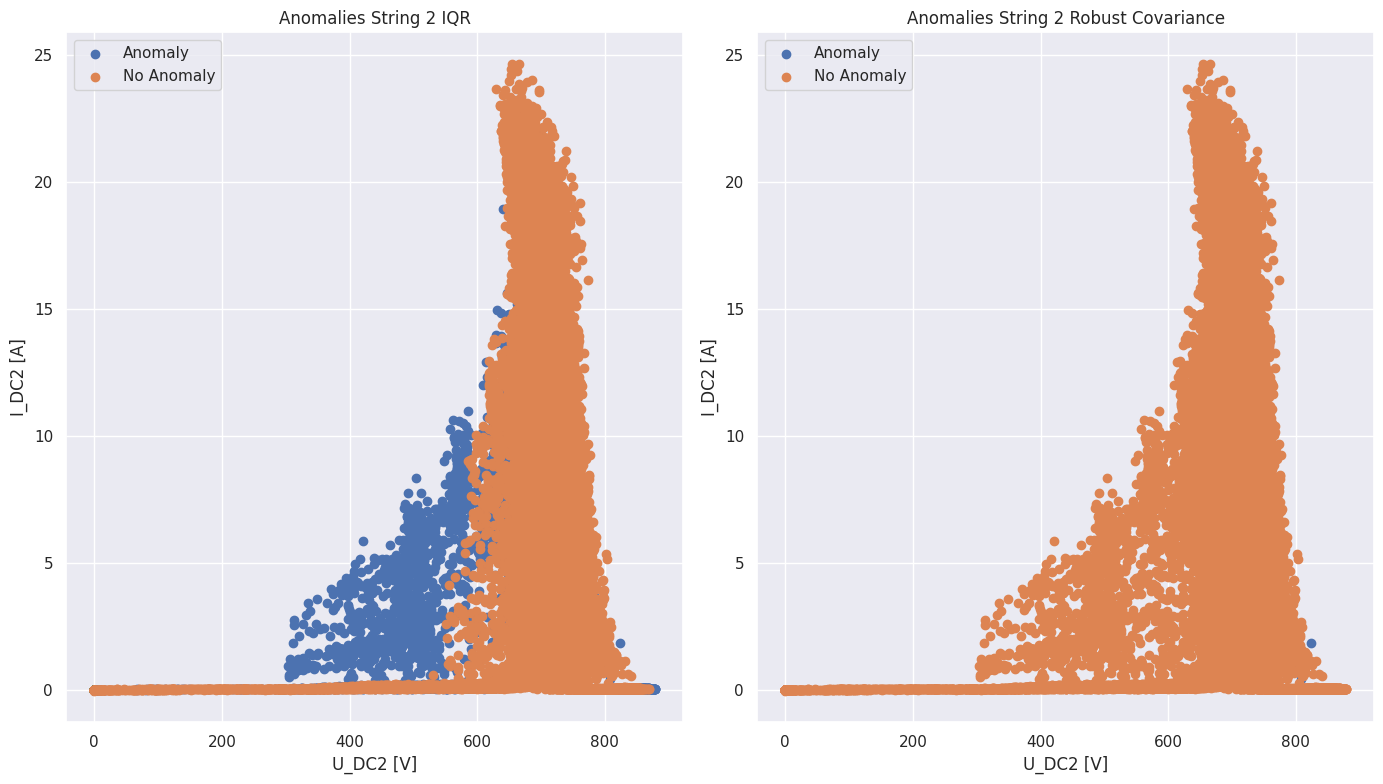

In [430]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_rc_train['U_DC2'], anomaly_rc_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_rc_train['U_DC2'], no_anomaly_rc_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Robust Covariance')


# Ajustes de diseño
plt.tight_layout()
plt.show()

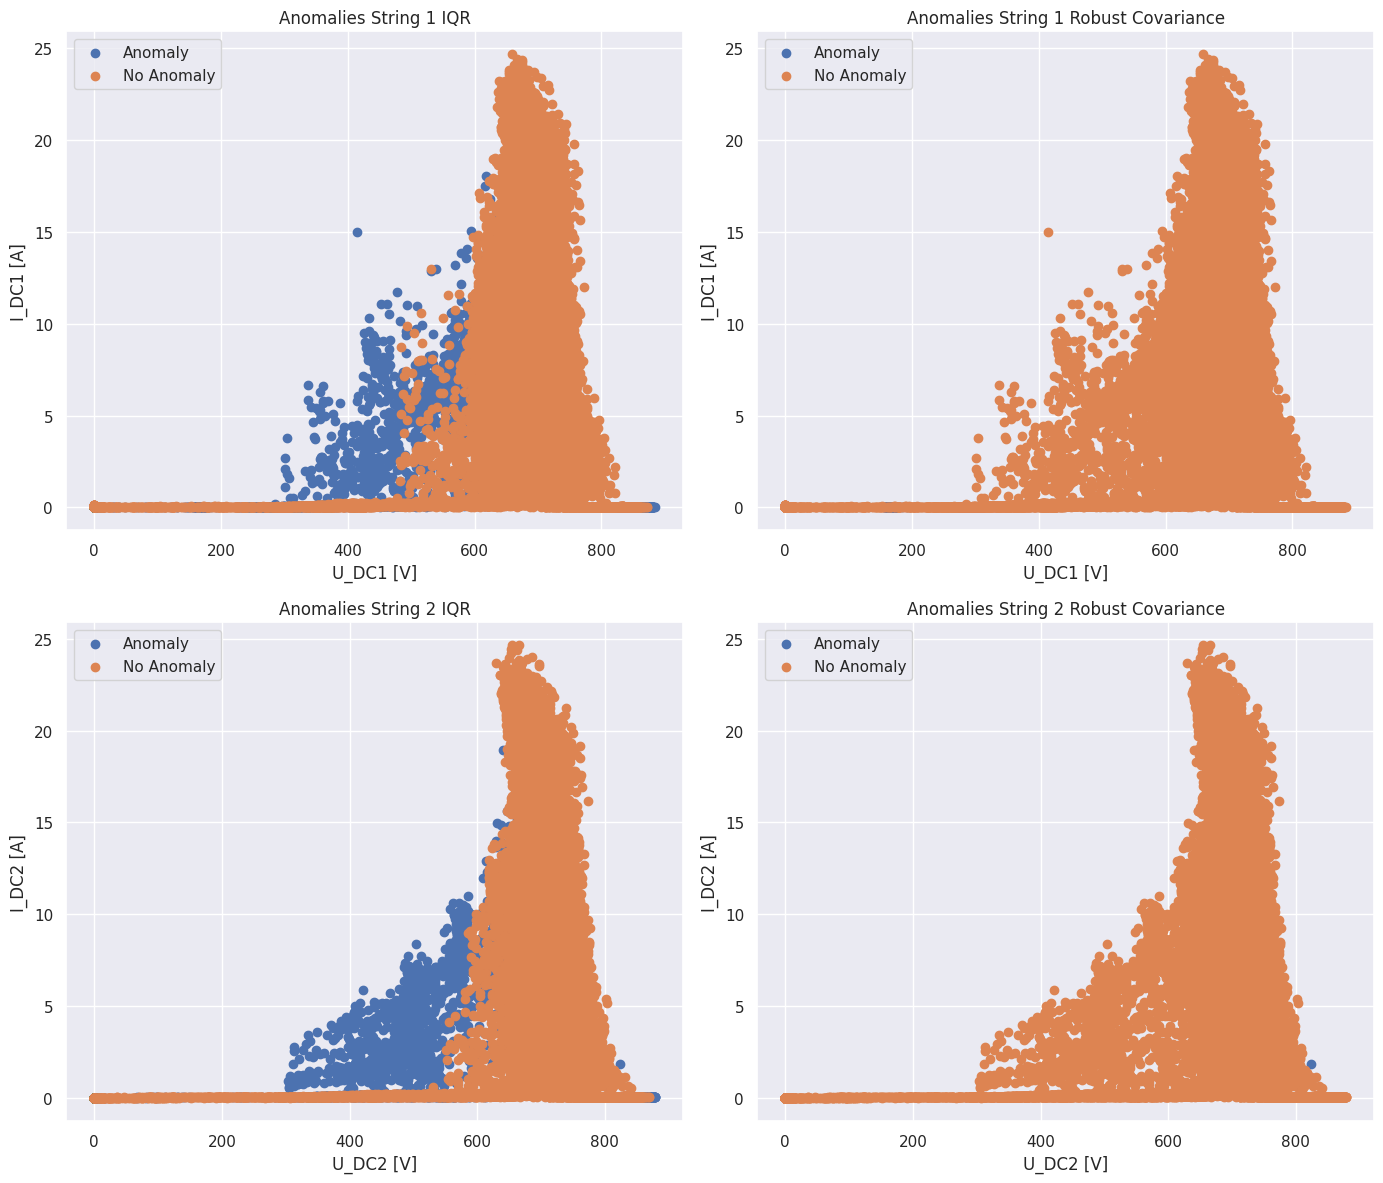

In [432]:
import matplotlib.pyplot as plt

# Create a single figure large enough for 4 plots
plt.figure(figsize=(14, 12))

# Gráfico 1: Top-Left (String 1, IQR)
plt.subplot(2, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')

# Gráfico 2: Top-Right (String 1, Robust Covariance)
plt.subplot(2, 2, 2)
plt.scatter(anomaly_rc_train['U_DC1'], anomaly_rc_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_rc_train['U_DC1'], no_anomaly_rc_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Robust Covariance')

# Gráfico 3: Bottom-Left (String 2, IQR)
plt.subplot(2, 2, 3)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')

# Gráfico 4: Bottom-Right (String 2, Robust Covariance)
plt.subplot(2, 2, 4)
plt.scatter(anomaly_rc_train['U_DC2'], anomaly_rc_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_rc_train['U_DC2'], no_anomaly_rc_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Robust Covariance')

# Ajustes de diseño
plt.tight_layout()
plt.show()

Datos de Prueba

In [433]:
# Predict anomalies on test data
pred_rc_model_test = best_model_rc.predict(x_test_rc)
df_test_rc['Anomaly'] = pred_rc_model_test

/tmp/ipykernel_6487/3689164463.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_rc['Anomaly'] = pred_rc_model_test


In [434]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

accuracy = accuracy_score(y_test_rc, pred_rc_model_test)
precision = precision_score(y_test_rc, pred_rc_model_test)
f1_score = f1_score(y_test_rc, pred_rc_model_test)
recall = recall_score(y_test_rc, pred_rc_model_test)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9095680258377069
Accuracy: 0.9775964453303434
F1_Score: 0.9435167251217086
Recall: 0.9800978792822186


In [435]:
def compute_tp_tn_fn_fp(y_act, y_pred):
    tp = sum((y_act == -1) & (y_pred == -1))  # true anomalies
    tn = sum((y_act ==  1) & (y_pred ==  1))  # true normals
    fn = sum((y_act == -1) & (y_pred ==  1))  # missed anomalies
    fp = sum((y_act ==  1) & (y_pred == -1))  # false alarms
    return tp, tn, fn, fp

tp,tn,fn,fp = compute_tp_tn_fn_fp(y_test_rc, pred_rc_model_test)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 38071
Number of TN: 9012
Number of FP: 183
Number of FN: 896


In [436]:
count0 = (df_test_rc['Anomaly'] == 1).sum()
count1 = (df_test_rc['Anomaly'] == -1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

9908 38254


In [437]:
anomaly_rc_test = df_test_rc[df_test_rc['Anomaly'] == -1]
no_anomaly_rc_test = df_test_rc[df_test_rc['Anomaly'] == 1]

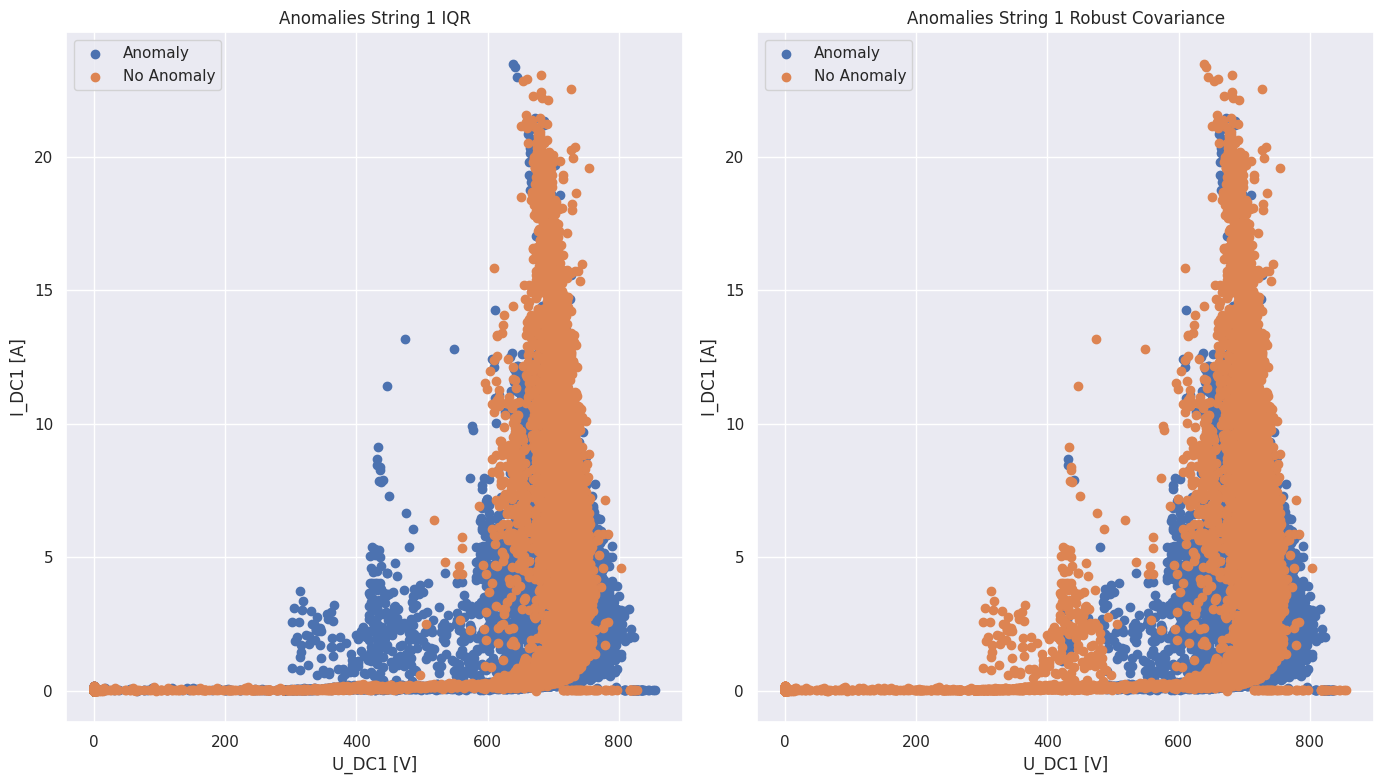

In [438]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_rc_test['U_DC1'], anomaly_rc_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_rc_test['U_DC1'], no_anomaly_rc_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('Anomalies String 1 Robust Covariance')


# Ajustes de diseño
plt.tight_layout()
plt.show()

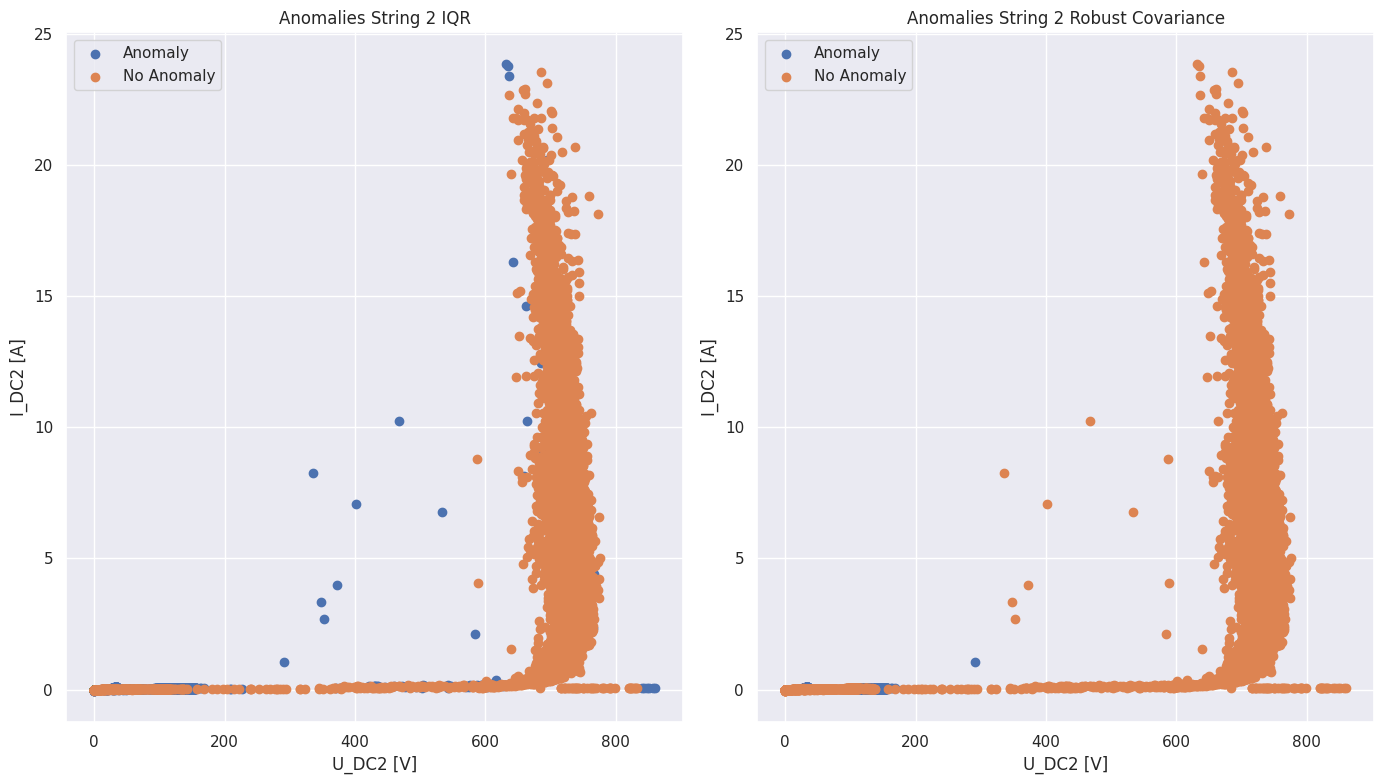

In [439]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_rc_test['U_DC2'], anomaly_rc_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_rc_test['U_DC2'], no_anomaly_rc_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('Anomalies String 2 Robust Covariance')


# Ajustes de diseño
plt.tight_layout()
plt.show()

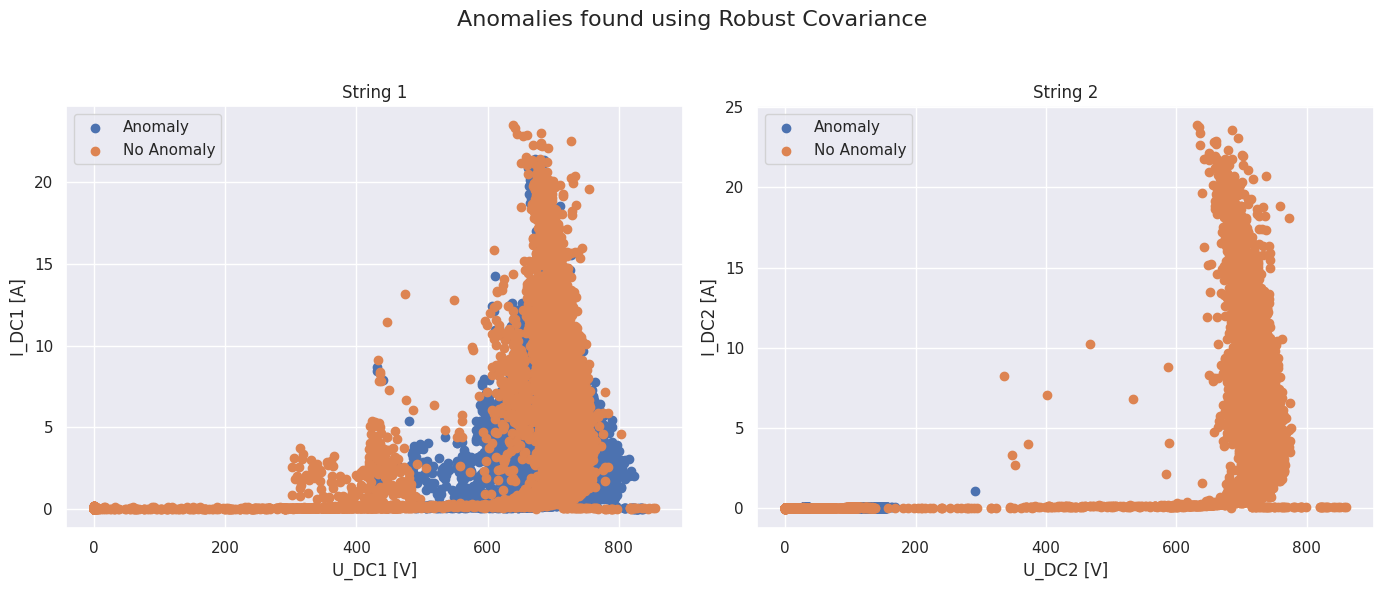

In [440]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle for the overarching figure title
plt.suptitle("Anomalies found using Robust Covariance", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
plt.scatter(anomaly_rc_test['U_DC1'], anomaly_rc_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_rc_test['U_DC1'], no_anomaly_rc_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
plt.scatter(anomaly_rc_test['U_DC2'], anomaly_rc_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_rc_test['U_DC2'], no_anomaly_rc_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping and render to screen
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
df_train_rc['Anomaly'] = df_train_rc['Anomaly'].replace({1: 0, -1: 1})
df_test_rc['Anomaly'] = df_test_rc['Anomaly'].replace({1: 0, -1: 1})

/tmp/ipykernel_2276/2915353417.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_rc['Anomaly'] = df_train_rc['Anomaly'].replace({1: 0, -1: 1})
/tmp/ipykernel_2276/2915353417.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_rc['Anomaly'] = df_test_rc['Anomaly'].replace({1: 0, -1: 1})


In [ ]:
df_train_rc['Anomaly'].unique()

array([0, 1])

In [ ]:
df_test_rc['Anomaly'].unique()

array([0, 1])

In [ ]:
ml_anomaly_df = pd.concat([df_train_rc, df_test_rc])

In [ ]:
ml_anomaly_df.to_csv('df_with_anomalies_rc.csv', sep=';', index=False, encoding='utf-8')

IQR Anomaly Plot

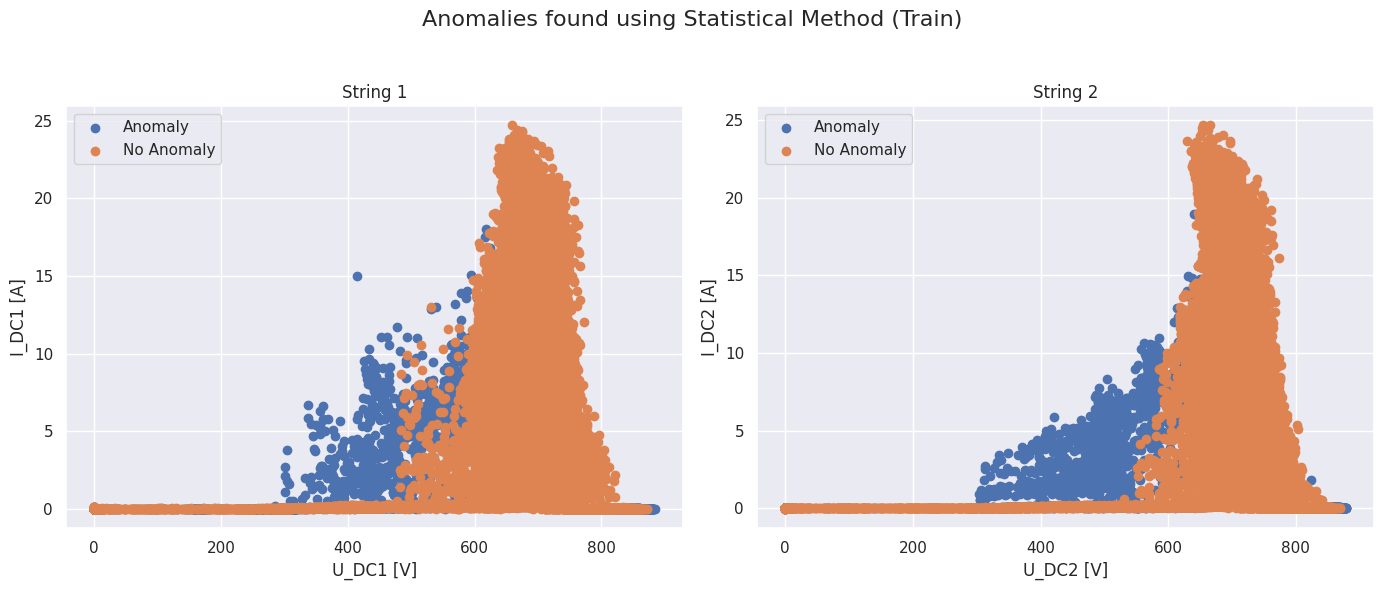

In [457]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle for the overarching figure title
plt.suptitle("Anomalies found using Statistical Method (Train)", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping and render to screen
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

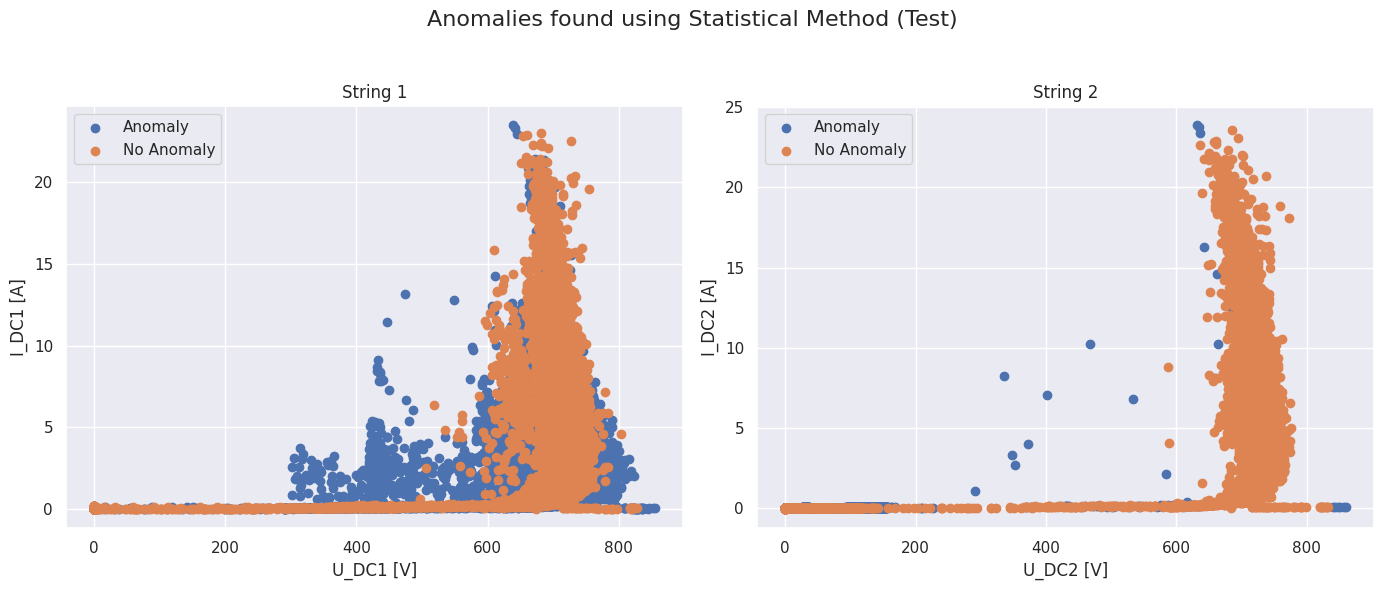

In [456]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle for the overarching figure title
plt.suptitle("Anomalies found using Statistical Method (Test)", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping and render to screen
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### *Método Autoencoder*

In [ ]:
df_ae = filtered_data

time = df_ae[['Timestamp']]
rows_ae = df_ae[['U_DC1','U_DC2','I_DC1','I_DC2']]

df_train_ae = df_ae[(df_ae['Timestamp'] < '2021-09-03')]
df_test_ae = df_ae[(df_ae['Timestamp'] >= '2021-09-03')]

rows_ae_train = df_train_ae[['U_DC1','U_DC2','I_DC1','I_DC2']]
rows_ae_test = df_test_ae[['U_DC1','U_DC2','I_DC1','I_DC2']]

x_train_ae = scaler.fit_transform(rows_ae_train)
x_test_ae = scaler.transform(rows_ae_test)

y_train_ae = np.array(merged_df_train['Anomaly'])
y_test_ae = np.array(merged_df_test['Anomaly'])


In [ ]:
y_train_ae

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
#Reshape LSTM Data

x_train_ae_lstm = x_train_ae.reshape(x_train_ae.shape[0],1,x_train_ae.shape[1])
print("Training data shape:", x_train_ae_lstm.shape)
x_test_ae_lstm = x_test_ae.reshape(x_test_ae.shape[0],1,x_test_ae.shape[1])
print("Testing data shape:", x_test_ae_lstm.shape)

Training data shape: (102236, 1, 4)
Testing data shape: (48162, 1, 4)


#### Datos de entrenamiento

In [ ]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
'''
#Model 1 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(64, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.001))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(64, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.001))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
"""

#Model 1 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(32, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.001))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(32, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.001))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
"""
'''
#Model 1 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(16, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.001))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(16, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.001))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 1 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(8, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.001))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(8, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.001))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 1 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.001))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.001))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model

'''
"""
#Model 2 - 5 layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))
    L1 = LSTM(16, activation='relu', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.01))(inputs)
    L1 = Dropout(0.1)(L1)
    L2 = LSTM(4, activation='relu', return_sequences=False,kernel_regularizer=regularizers.l2(0.01))(L1)
    L2 = Dropout(0.1)(L2)
    L3 = RepeatVector(X.shape[1])(L2)
    L4 = LSTM(4, activation='relu', return_sequences=True,kernel_regularizer=regularizers.l2(0.01))(L3)
    L4 = Dropout(0.1)(L4)
    L5 = LSTM(16, activation='relu', return_sequences=True,kernel_regularizer=regularizers.l2(0.01))(L4)
    L5 = Dropout(0.1)(L5)

    output = TimeDistributed(Dense(X.shape[2]))(L5)
    model = Model(inputs=inputs, outputs=output)
    return model
"""


"\n#Model 2 - 5 layers without counting input and output\ndef autoencoder_model(X):\n    inputs = Input(shape=(X.shape[1], X.shape[2]))\n    L1 = LSTM(16, activation='relu', return_sequences=True,\n              kernel_regularizer=regularizers.l2(0.01))(inputs)\n    L1 = Dropout(0.1)(L1)\n    L2 = LSTM(4, activation='relu', return_sequences=False,kernel_regularizer=regularizers.l2(0.01))(L1)\n    L2 = Dropout(0.1)(L2)\n    L3 = RepeatVector(X.shape[1])(L2)\n    L4 = LSTM(4, activation='relu', return_sequences=True,kernel_regularizer=regularizers.l2(0.01))(L3)\n    L4 = Dropout(0.1)(L4)\n    L5 = LSTM(16, activation='relu', return_sequences=True,kernel_regularizer=regularizers.l2(0.01))(L4)\n    L5 = Dropout(0.1)(L5)\n\n    output = TimeDistributed(Dense(X.shape[2]))(L5)\n    model = Model(inputs=inputs, outputs=output)\n    return model\n"

In [ ]:
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.002))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.002))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.005))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.005))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.008))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.008))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''

'''

#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.01))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.01))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.1))(inputs)
    L1 = Dropout(0.05)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.1))(L2)
    L3 = Dropout(0.05)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''


In [ ]:
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.005))(inputs)
    L1 = Dropout(0.1)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.005))(L2)
    L3 = Dropout(0.1)(L3)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.005))(inputs)
    L1 = Dropout(0.15)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.005))(L2)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''

#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.005))(inputs)
    L1 = Dropout(0.2)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.005))(L2)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model

'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.005))(inputs)
    L1 = Dropout(0.25)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.005))(L2)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''
'''
#Model 2 - 3 Layers without counting input and output
def autoencoder_model(X):
    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)
    L1 = LSTM(4, activation='tanh', return_sequences=False,
              kernel_regularizer=regularizers.l2(0.005))(inputs)
    L1 = Dropout(0.3)(L1)
    L2 = RepeatVector(X.shape[1])(L1)
    L3 = LSTM(4, activation='tanh', return_sequences=True,
              kernel_regularizer=regularizers.l2(0.005))(L2)
    L1 = Dropout(0.3)(L1)
    output = TimeDistributed(Dense(X.shape[2]))(L3)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return model
'''

"\n#Model 2 - 3 Layers without counting input and output\ndef autoencoder_model(X):\n    inputs = Input(shape=(X.shape[1], X.shape[2]))  # (timesteps, 4 features)\n    L1 = LSTM(4, activation='tanh', return_sequences=False,\n              kernel_regularizer=regularizers.l2(0.005))(inputs)\n    L1 = Dropout(0.3)(L1)\n    L2 = RepeatVector(X.shape[1])(L1)\n    L3 = LSTM(4, activation='tanh', return_sequences=True,\n              kernel_regularizer=regularizers.l2(0.005))(L2)\n    L1 = Dropout(0.3)(L1)\n    output = TimeDistributed(Dense(X.shape[2]))(L3)\n    model = Model(inputs=inputs, outputs=output)\n    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')\n    return model\n"

In [ ]:
ae_model = autoencoder_model(x_train_ae_lstm)
ae_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1, 4)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 4)              │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 1, 4)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 1, 4)           │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 1, 4)           │            20 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 308 (1.20 KB)

 Trainable params: 308 (1.20 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
nb_epochs = 50
batch_size = 32
history = ae_model.fit(x_train_ae_lstm, x_train_ae_lstm, epochs=nb_epochs, batch_size=batch_size,
                    validation_split=0.1).history

Epoch 1/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: 0.4379 - val_loss: 0.3022
Epoch 2/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - loss: 0.2604 - val_loss: 0.2486
Epoch 3/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.2477 - val_loss: 0.2287
Epoch 4/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.2249 - val_loss: 0.2401
Epoch 5/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - loss: 0.2141 - val_loss: 0.2292
Epoch 6/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - loss: 0.2093 - val_loss: 0.2190
Epoch 7/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - loss: 0.2062 - val_loss: 0.2192
Epoch 8/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - loss: 0.2039 - val_loss: 0.2233
Epoch 9/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.2011 - val_loss: 0.2109
Epoch 10/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - loss: 0.2006 - val_loss: 0.2128
Epoch 11/50
2876/2876 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - loss: 0.1992 - val_loss: 0.2043
Epoch 12/50
2876/28

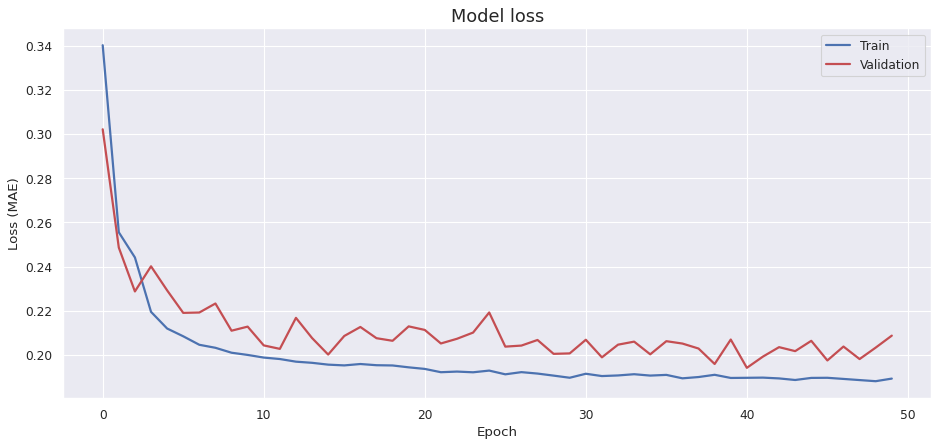

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6), dpi=80)
ax.plot(history['loss'], 'b', label='Train', linewidth=2)
ax.plot(history['val_loss'], 'r', label='Validation', linewidth=2)
ax.set_title('Model loss', fontsize=16)
ax.set_ylabel('Loss (MAE)')
ax.set_xlabel('Epoch')
ax.legend(loc='upper right')
plt.show()

In [ ]:
x_pred_ae = ae_model.predict(x_train_ae_lstm)
x_pred_ae = x_pred_ae.reshape(x_pred_ae.shape[0], x_pred_ae.shape[2])
x_pred_ae = pd.DataFrame(x_pred_ae, columns=rows_ae_train.columns)

3195/3195 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


In [ ]:
scored = pd.DataFrame()
x_train_layers = x_train_ae_lstm.reshape(x_train_ae_lstm.shape[0], x_train_ae_lstm.shape[2])
scored['Loss_mae'] = np.mean(np.abs(x_pred_ae - x_train_layers),axis=1)

/tmp/ipython-input-2877929277.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(scored['Loss_mae'], bins = 100, kde= True, color = 'blue');


(0.0, 0.3)

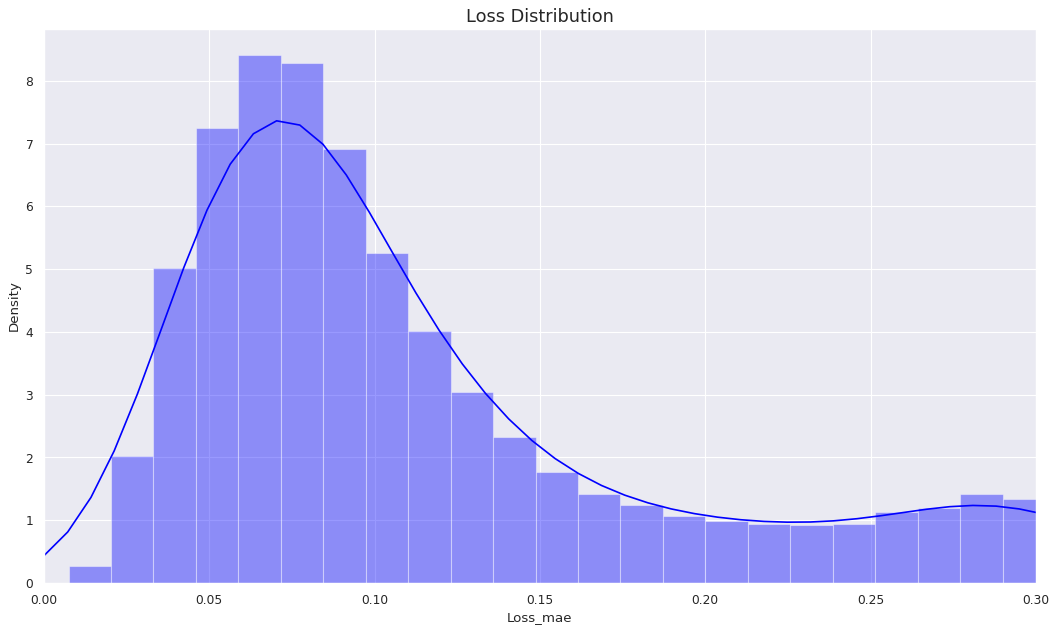

In [ ]:
plt.figure(figsize=(16,9), dpi=80)
plt.title('Loss Distribution', fontsize=16)
sns.distplot(scored['Loss_mae'], bins = 100, kde= True, color = 'blue');
plt.xlim([0.0,0.3])

In [ ]:
scored['Threshold'] = 0.225
scored['Anomaly'] = scored['Loss_mae'] > scored['Threshold']
anomalies_ae_train = np.array(scored['Anomaly'])
anomalies_ae_train = anomalies_ae_train.astype(int)

In [ ]:
np.unique(anomalies_ae_train)

array([0, 1])

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


accuracy = accuracy_score(anomalies_ae_train,y_train_ae)
precision = precision_score(anomalies_ae_train,y_train_ae)
f1_score = f1_score(anomalies_ae_train,y_train_ae)
recall = recall_score(anomalies_ae_train,y_train_ae)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

anomalies_ae_train[anomalies_ae_train==1].shape

Precision: 0.938073908174692
Accuracy: 0.8493387847724871
F1_Score: 0.5210063127779333
Recall: 0.36065785508244713


(23227,)

Text(0.5, 1.0, 'Confusion Matrix for LSTM Autoencoder - Train Data')

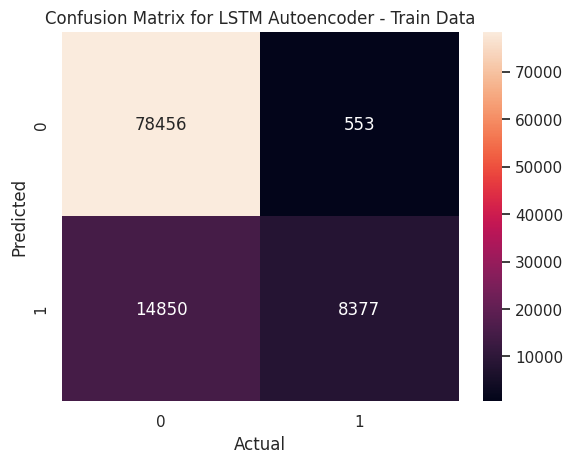

In [ ]:
cm_train = confusion_matrix(anomalies_ae_train,y_train_ae)
sns.heatmap(cm_train,annot=True, fmt='g')
# Set the axis labels and title
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix for LSTM Autoencoder - Train Data')

In [ ]:
#Make Confusion Matrix and Evaluate TP, TN, FN, FP
def compute_tp_tn_fn_fp(y_act, y_pred):
    tp = sum((y_act == 1) & (y_pred == 1))
    tn = sum((y_act == 0) & (y_pred == 0))
    fn = sum((y_act == 1) & (y_pred == 0))
    fp = sum((y_act == 0) & (y_pred == 1))
    return tp, tn, fp, fn

tp,tn,fn,fp = compute_tp_tn_fn_fp(anomalies_ae_train,y_train_ae)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

def specificity(tn,fp):
    return tn/(tn+fp)


specificity_train = specificity(tn,fp)
print('Specificity:'+ str(specificity_train))

Number of TP: 8377
Number of TN: 78456
Number of FP: 14850
Number of FN: 553
Specificity:0.8408462478297216


In [ ]:
df_train_ae['Anomaly'] = anomalies_ae_train

/tmp/ipython-input-2267264089.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_ae['Anomaly'] = anomalies_ae_train


In [ ]:
count0 = (df_train_ae['Anomaly'] == 0).sum()
count1 = (df_train_ae['Anomaly'] == 1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

79009 23227


In [ ]:
anomaly_ae_train = df_train_ae[df_train_ae['Anomaly'] == 1]
no_anomaly_ae_train = df_train_ae[df_train_ae['Anomaly'] == 0]

In [ ]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_train['Timestamp'].isin(anomaly_ae_train['Timestamp']).sum())

8377


/tmp/ipython-input-2502731845.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_train['Timestamp'].isin(anomaly_ae_train['Timestamp']).sum())


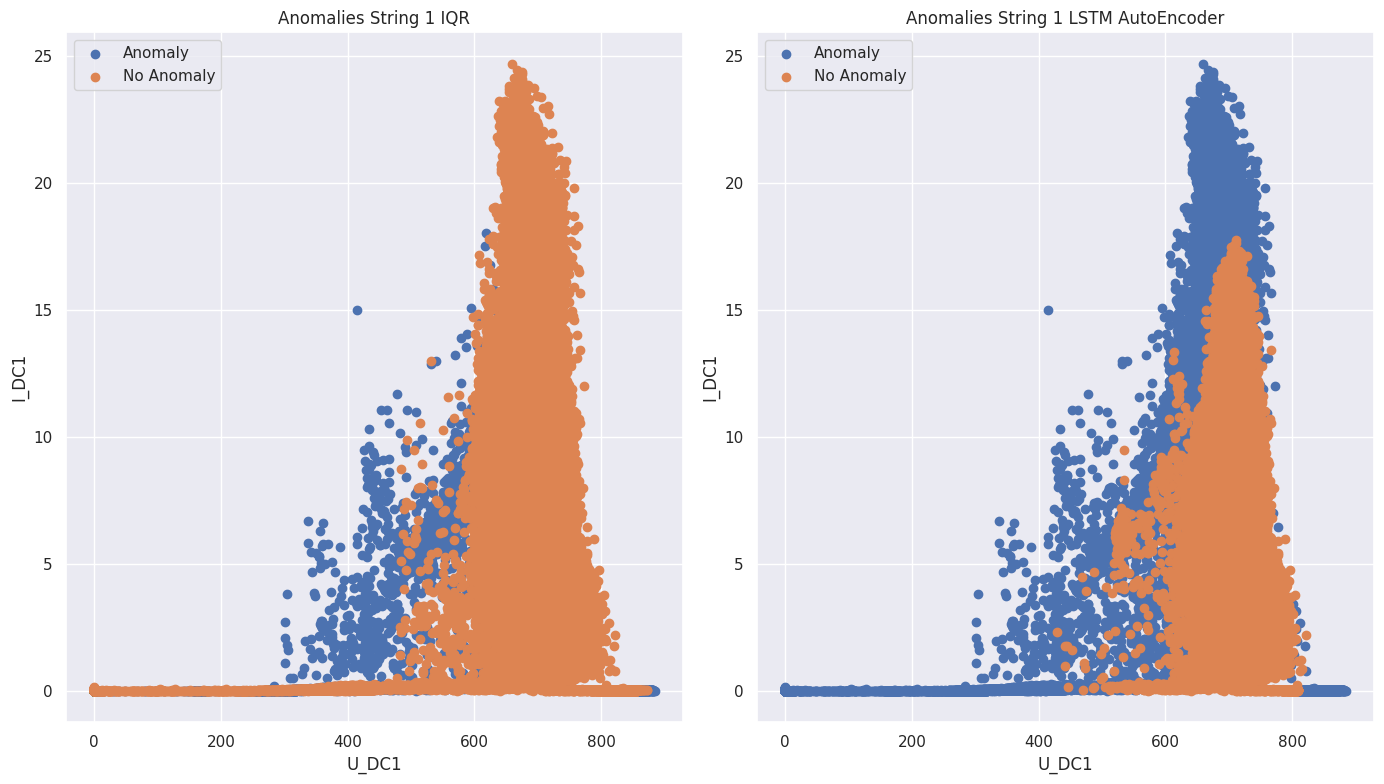

In [ ]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC1'], anomaly_iqr_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC1'], no_anomaly_iqr_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1')
plt.ylabel('I_DC1')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_ae_train['U_DC1'], anomaly_ae_train['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_ae_train['U_DC1'], no_anomaly_ae_train['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1')
plt.ylabel('I_DC1')
plt.legend()
plt.title('Anomalies String 1 LSTM AutoEncoder')


# Ajustes de diseño
plt.tight_layout()
plt.show()

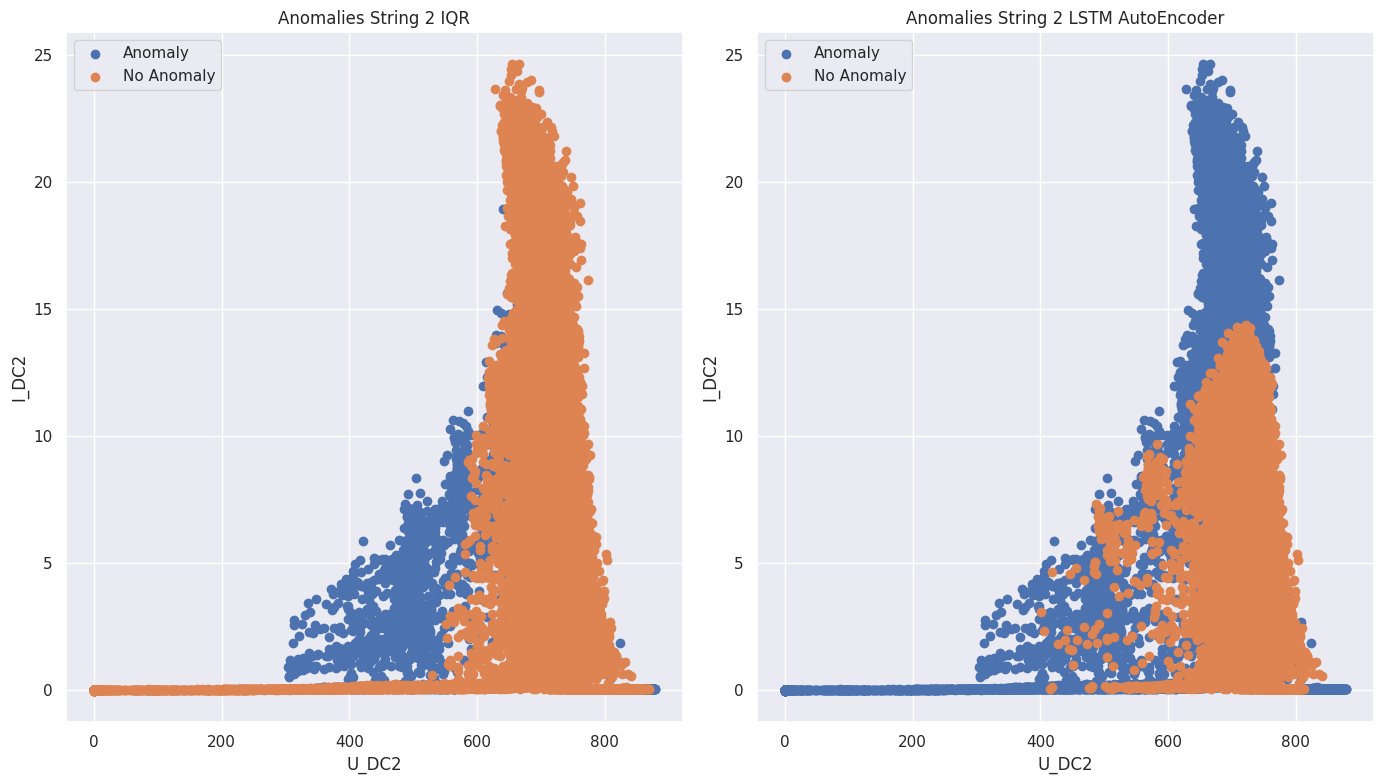

In [ ]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_train['U_DC2'], anomaly_iqr_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_train['U_DC2'], no_anomaly_iqr_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2')
plt.ylabel('I_DC2')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_ae_train['U_DC2'], anomaly_ae_train['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_ae_train['U_DC2'], no_anomaly_ae_train['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2')
plt.ylabel('I_DC2')
plt.legend()
plt.title('Anomalies String 2 LSTM AutoEncoder')


# Ajustes de diseño
plt.tight_layout()
plt.show()

#### Datos de Prueba

In [ ]:
x_pred_ae_test = ae_model.predict(x_test_ae_lstm)
x_pred_ae_test = x_pred_ae_test.reshape(x_pred_ae_test.shape[0], x_pred_ae_test.shape[2])
x_pred_ae_test = pd.DataFrame(x_pred_ae_test, columns=rows_ae_test.columns)

1506/1506 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

scored_test = pd.DataFrame()
x_test_layers = x_test_ae_lstm.reshape(x_test_ae_lstm.shape[0], x_test_ae_lstm.shape[2])
scored_test['Loss_mae'] = np.mean(np.abs(x_pred_ae_test-x_test_layers), axis = 1)
scored_test['Threshold'] = 0.225
scored_test['Anomaly'] = scored_test['Loss_mae'] > scored_test['Threshold']
anomalies_ae_test = np.array(scored_test['Anomaly'])
anomalies_ae_test = anomalies_ae_test.astype(int)
accuracy = accuracy_score(anomalies_ae_test,y_test_ae)
precision = precision_score(anomalies_ae_test,y_test_ae)
f1_score = f1_score(anomalies_ae_test,y_test_ae)
recall = recall_score(anomalies_ae_test,y_test_ae)
print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))
anomalies_ae_test[anomalies_ae_test==1].shape

Precision: 0.9995380706751867
Accuracy: 0.9593040156139695
F1_Score: 0.9754564351724311
Recall: 0.9525078868210609


(40891,)

Text(0.5, 1.0, 'Confusion Matrix for LSTM Autoencoder - Test Data')

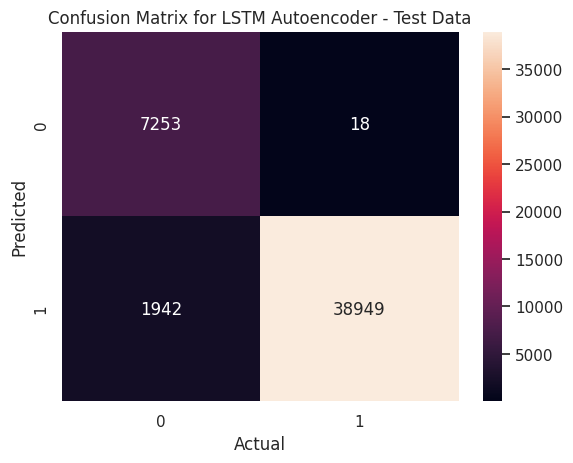

In [ ]:
cm_test = confusion_matrix(anomalies_ae_test,y_test_ae)
sns.heatmap(cm_test,annot=True, fmt='g')
# Set the axis labels and title
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix for LSTM Autoencoder - Test Data')

In [ ]:
tp,tn,fn,fp = compute_tp_tn_fn_fp(anomalies_ae_test,y_test_ae)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))


specificity_test = specificity(tn,fp)
print('Specificity:'+ str(specificity_test))


Number of TP: 38949
Number of TN: 7253
Number of FP: 1942
Number of FN: 18
Specificity:0.7887982599238716


In [ ]:
df_test_ae['Anomaly'] = anomalies_ae_test

/tmp/ipython-input-3249493910.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_ae['Anomaly'] = anomalies_ae_test


In [ ]:
count0 = (df_test_ae['Anomaly'] == 0).sum()
count1 = (df_test_ae['Anomaly'] == 1).sum()

#Contar números de anomalías detectadas y no detectadas
print(count0, count1)

7271 40891


In [ ]:
anomaly_ae_test = df_test_ae[df_test_ae['Anomaly'] == 1]
no_anomaly_ae_test = df_test_ae[df_test_ae['Anomaly'] == 0]

In [ ]:
#Coincidencias con modelo estadístico
print(anomaly_iqr_test['Timestamp'].isin(anomaly_ae_test['Timestamp']).sum())

38949


/tmp/ipython-input-1705076727.py:2: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  print(anomaly_iqr_test['Timestamp'].isin(anomaly_ae_test['Timestamp']).sum())


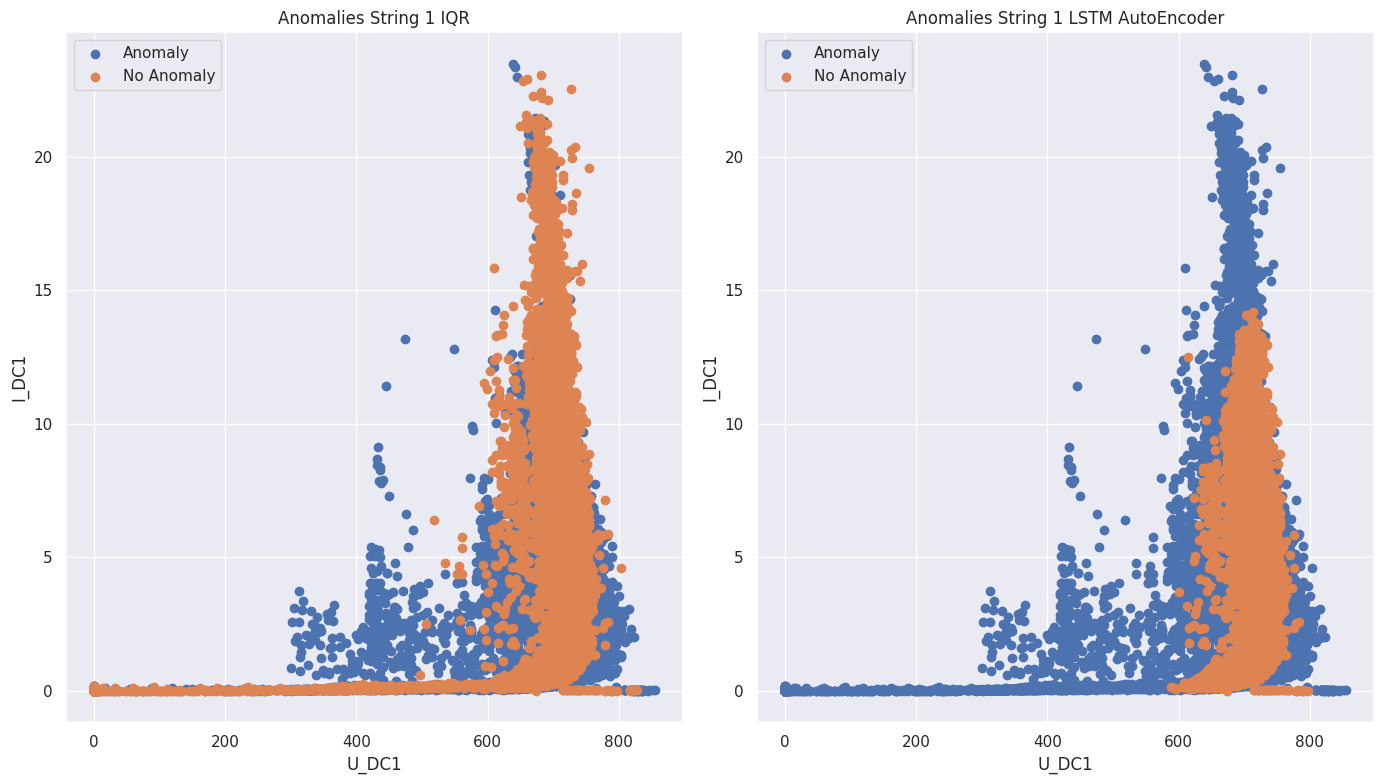

In [ ]:
#STRING1

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1')
plt.ylabel('I_DC1')
plt.legend()
plt.title('Anomalies String 1 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_ae_test['U_DC1'], anomaly_ae_test['I_DC1'], label='Anomaly')
plt.scatter(no_anomaly_ae_test['U_DC1'], no_anomaly_ae_test['I_DC1'], label='No Anomaly')
plt.xlabel('U_DC1')
plt.ylabel('I_DC1')
plt.legend()
plt.title('Anomalies String 1 LSTM AutoEncoder')


# Ajustes de diseño
plt.tight_layout()
plt.show()

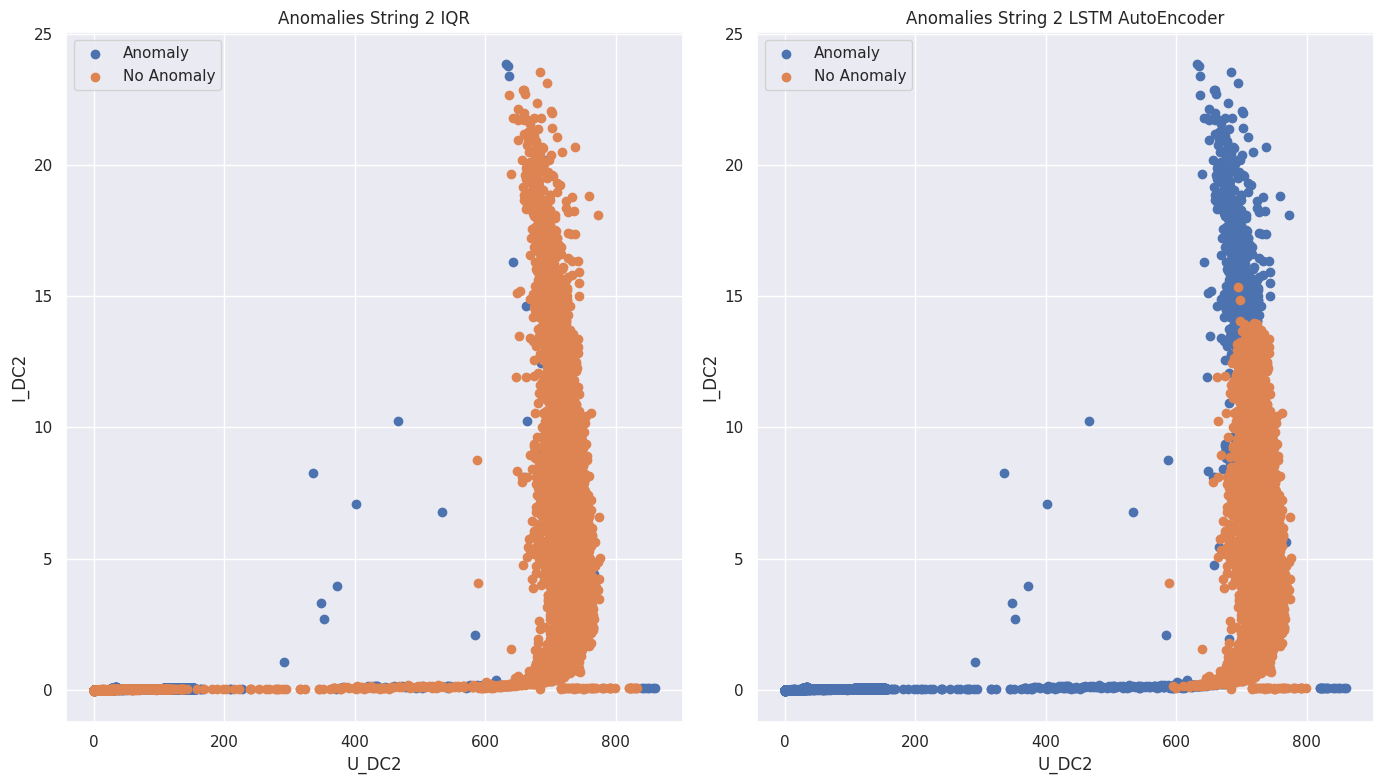

In [ ]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))


# Gráfico 1
plt.subplot(1, 2, 1)
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2')
plt.ylabel('I_DC2')
plt.legend()
plt.title('Anomalies String 2 IQR')


#Gráfico 2
plt.subplot(1, 2, 2)
plt.scatter(anomaly_ae_test['U_DC2'], anomaly_ae_test['I_DC2'], label='Anomaly')
plt.scatter(no_anomaly_ae_test['U_DC2'], no_anomaly_ae_test['I_DC2'], label='No Anomaly')
plt.xlabel('U_DC2')
plt.ylabel('I_DC2')
plt.legend()
plt.title('Anomalies String 2 LSTM AutoEncoder')


# Ajustes de diseño
plt.tight_layout()
plt.show()

### **EXPORTAR DATOS DE MÉTODO: LSTM AUTOENCODER**

In [ ]:
ml_anomaly_df = pd.concat([df_train_ae,df_test_ae])

In [ ]:
ml_anomaly_df

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly
131,2019-08-02 16:25:00,777.010,768.710,2.700,2.607,0
132,2019-08-02 16:30:00,761.130,745.964,3.862,3.748,0
133,2019-08-02 16:35:00,736.754,742.908,3.228,3.192,0
134,2019-08-02 16:40:00,731.928,732.224,2.568,2.484,0
135,2019-08-02 16:45:00,723.546,720.698,1.654,1.640,0
...,...,...,...,...,...,...
203056,2023-06-02 10:10:00,712.860,698.410,15.514,15.758,1
203057,2023-06-02 10:15:00,703.810,696.148,16.136,16.278,1
203058,2023-06-02 10:20:00,702.586,466.782,16.520,10.250,1
203059,2023-06-02 10:25:00,703.080,32.316,15.754,0.080,1


In [ ]:
ml_anomaly_df.to_csv('df_with_anomalies_drop3.csv', sep=';', index=False, encoding='utf-8')

In [ ]:
#Guardar modelo
ae_model.save("autoencoder_model_drop3.h5")

In [ ]:
#Guardar pesos
ae_model.save_weights("autoencoder_drop3.weights.h5")